# COMP9444 Project 013 — Biomedical Named Entity Recognition

We compare general-domain, biomedical and scientific pretrained transformers for disease mention recognition.

## 1. Environment Setup
### 1.1 Environment

Use the existing `9444/.venv` environment.

In [1]:
from pathlib import Path
import sys, os, platform, importlib.metadata as metadata, warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')

candidates = [Path.cwd(), *Path.cwd().parents]
locations = [location for p in candidates for location in (p, p / 'project')]
ROOT = next((p.resolve() for p in locations
             if (p / 'notebooks/project013.ipynb').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open notebooks/project013.ipynb inside the project directory structure.')
EXPECTED_ENV = ROOT.parent / '.venv'
if not EXPECTED_ENV.is_dir() or Path(sys.prefix).resolve() != EXPECTED_ENV.resolve():
    raise RuntimeError(f'Select the existing {EXPECTED_ENV} kernel. Current Python: {sys.executable}. '
                       'No interpreter was switched and no environment was created.')
required = ['torch','transformers','pandas','numpy','matplotlib','nltk','seqeval',
            'accelerate','requests','huggingface_hub','safetensors']
missing = []
for package in required:
    try: metadata.version(package)
    except metadata.PackageNotFoundError: missing.append(package)
if missing:
    raise RuntimeError(f'Missing dependencies: {missing}. Install using "{sys.executable}" -m pip '
                       'install -r project/requirements.txt from 9444, then restart this kernel.')
if metadata.version('transformers') != '4.57.6':
    raise RuntimeError('These experiments use transformers==4.57.6. Install that version in the existing environment.')

### 1.2 Execution mode

`RETRAIN=False` recomputes Dev predictions from saved checkpoints. Set `RETRAIN=True` to fine-tune from pretrained weights.
`TRAIN_NEW_MODELS=True` trains only missing PubMedBERT/SciBERT baselines; existing BERT/BioBERT experiments are reused.

In [2]:
import json, hashlib, io, re, zipfile, gc, shutil, time
from collections import Counter
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch, transformers
from IPython.display import display, Markdown
from nltk.tokenize.punkt import PunktParameters, PunktSentenceTokenizer
from huggingface_hub import HfApi, snapshot_download
from seqeval.metrics import precision_score, recall_score, f1_score
from seqeval.scheme import IOB2
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
    DataCollatorForTokenClassification, Trainer, TrainingArguments, set_seed)
from torch.utils.data import DataLoader

RETRAIN = False
TRAIN_NEW_MODELS = False
RUN_TAG = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') if RETRAIN or TRAIN_NEW_MODELS else None
torch.set_num_threads(4)
os.environ.update(TOKENIZERS_PARALLELISM='false', HF_HUB_DISABLE_PROGRESS_BARS='1',
                  HF_HUB_DISABLE_XET='1', HF_HUB_DISABLE_SYMLINKS_WARNING='1')
os.environ['HF_HOME'] = str(ROOT / 'models/.hf_cache')
for name in ['data/raw','data/processed','models/bert_base','models/biobert','results/eda',
             'results/bert_base','results/biobert','results/pubmedbert','results/scibert',
             'models/pubmedbert','models/scibert','results/comparison']:
    (ROOT / name).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':120, 'savefig.dpi':220, 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
environment = {'python_executable':sys.executable, 'python':platform.python_version(),
    'torch':torch.__version__, 'transformers':transformers.__version__,
    'cuda_available':torch.cuda.is_available(), 'cuda_build':torch.version.cuda,
    'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
    'kernel':'project013', 'mode':'fresh training' if RETRAIN else 'checkpoint reproduction'}
display(pd.Series(environment, name='Current environment').to_frame())

,Current environment
python_executable,\.venv\Scri...
python,3.10.11
torch,2.14.0+cu130
transformers,4.57.6
cuda_available,True
cuda_build,13.0
gpu,NVIDIA GeForce RTX 3070 Laptop GPU
kernel,project013
mode,checkpoint reproduction


In [3]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_text_once(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        if path.read_text(encoding='utf-8') != text:
            raise FileExistsError(f'Existing artifact differs; refusing to overwrite: {path}')
    else:
        path.write_text(text, encoding='utf-8')

def write_json(path, value):
    write_text_once(path, json.dumps(value, indent=2, ensure_ascii=False))

def write_jsonl(path, records):
    write_text_once(path, ''.join(json.dumps(row, ensure_ascii=False) + chr(10) for row in records))

def read_jsonl(path):
    with Path(path).open(encoding='utf-8') as stream:
        return [json.loads(line) for line in stream if line.strip()]

## 2. Data Acquisition and Loading
### 2.1 NCBI Disease Corpus

The [NCBI Disease Corpus](https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/) contains 793 PubMed title/abstract records and 6,892 disease mentions. We use its official Train/Dev/Test split of 593/100/100 records.

The source categories `SpecificDisease`, `DiseaseClass`, `Modifier`, and `CompositeMention` are combined into one recognition class, **Disease**. Original categories and MeSH/OMIM identifiers are retained; concept normalization is outside the task.

### 2.2 Data integrity

Archive and text SHA-256 hashes identify the corpus version; ZIP contents are also checked by CRC.

In [4]:
SOURCE = 'https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/'
FILES = {'train':'NCBItrainset_corpus', 'dev':'NCBIdevelopset_corpus', 'test':'NCBItestset_corpus'}
ARCHIVE_SHA256 = {'train': '26157233d70aeda0b2ac1dda4fc9369b0717bd888f5afe511d0c1c6a5ad307a0', 'dev': '61681ad09356619c8f4f3e1738663dd007ad0135720fdc90195120fea944cbe9', 'test': 'b978442f39c739deb6619c70e7b07327d9eb1b71aff64996c02a592435583f46'}
TEXT_SHA256 = {'train': '3577a122567916449f4127289aa6f84d49c73ff32bf64b3be5ff14e019c98c38', 'dev': '02db559974624ae9cbe6cd95d64d953e6926bb63afb6b25b63e53bd8b41a4b55', 'test': '61c8050bf6979ef7b943ec1158dfc03b651ea3367d4c37356f9de4841e85c9a3'}
LABELS = ['O','B-Disease','I-Disease']
label2id = {label:i for i,label in enumerate(LABELS)}
id2label = dict(enumerate(LABELS))

In [5]:
def acquire(root):
    raw = Path(root) / 'data/raw'
    raw.mkdir(parents=True, exist_ok=True)
    old = raw / 'provenance.json'
    recorded = json.loads(old.read_text(encoding='utf-8')) if old.exists() else None
    manifest = {'source':SOURCE, 'retrieved_utc':datetime.now(timezone.utc).isoformat(), 'files':{}}
    for split,stem in FILES.items():
        archive, text_path = raw / (stem+'.zip'), raw / (stem+'.txt')
        if text_path.exists():
            assert sha256(text_path) == TEXT_SHA256[split], f'Raw text changed: {text_path}'
        if not text_path.exists() and not archive.exists():
            response = requests.get(SOURCE+archive.name, timeout=90)
            response.raise_for_status()
            assert hashlib.sha256(response.content).hexdigest() == ARCHIVE_SHA256[split]
            archive.write_bytes(response.content)
        if archive.exists():
            assert sha256(archive) == ARCHIVE_SHA256[split], f'Cached archive changed: {archive}'
            with zipfile.ZipFile(archive) as zipped:
                assert zipped.testzip() is None
                original = zipped.read(stem+'.txt')
            assert hashlib.sha256(original).hexdigest() == TEXT_SHA256[split]
            if text_path.exists():
                assert text_path.read_bytes() == original
            else:
                text_path.write_bytes(original)
        assert text_path.exists() and sha256(text_path) == TEXT_SHA256[split]
        manifest['files'][split] = {'url':SOURCE+archive.name, 'archive':archive.name,
            'sha256':ARCHIVE_SHA256[split], 'extracted':[stem+'.txt']}
    if recorded is not None:
        manifest['retrieved_utc'] = recorded['retrieved_utc']
        assert manifest == recorded, 'Existing corpus provenance differs from the pinned version.'
    else:
        write_json(old, manifest)
    return manifest

provenance = acquire(ROOT)
display(pd.DataFrame(provenance['files']).T[['url','sha256']])
print('Original retrieval (UTC):', provenance['retrieved_utc'])

,url,sha256
train,https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan...,26157233d70aeda0b2ac1dda4fc9369b0717bd888f5afe...
dev,https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan...,61681ad09356619c8f4f3e1738663dd007ad0135720fdc...
test,https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan...,b978442f39c739deb6619c70e7b07327d9eb1b71aff649...


Original retrieval (UTC): 2026-11-03T10:41:09.517873+00:00


### 2.3 Original annotation format

PubTator records contain `PMID|t|title`, `PMID|a|abstract`, followed by tab-separated `PMID, start, end, surface, category, concept_id` annotations. Offsets are zero-based and end-exclusive in `title + " " + abstract`, so whitespace must be preserved.

In [6]:
raw_lines = (ROOT / 'data/raw/NCBItrainset_corpus.txt').read_text(encoding='utf-8-sig').splitlines()
print(next(line for line in raw_lines if '|t|' in line))
print('\n'.join([line for line in raw_lines if '\t' in line][:6]))

10192393|t|A common human skin tumour is caused by activating mutations in beta-catenin.
10192393	15	26	skin tumour	DiseaseClass	D012878
10192393	443	449	cancer	DiseaseClass	D009369
10192393	483	496	colon cancers	DiseaseClass	D003110
10192393	539	565	adenomatous polyposis coli	SpecificDisease	D011125
10192393	567	570	APC	SpecificDisease	D011125
10192393	670	698	colon and some other cancers	CompositeMention	D003110|D009369


### 2.4 Document loading

In [7]:
def parse_pubtator(path, split):
    documents, occurrences = [], Counter()
    for line in Path(path).read_text(encoding="utf-8-sig").splitlines():
        if "|t|" in line:
            pmid, title = line.split("|t|", 1)
            occurrences[pmid] += 1
            documents.append({"id": f"{split}:{pmid}:{occurrences[pmid]}", "pmid": pmid,
                              "split": split, "title": title, "annotations": []})
        elif "|a|" in line:
            pmid, abstract = line.split("|a|", 1)
            assert documents[-1]["pmid"] == pmid
            documents[-1].update(abstract=abstract, text=documents[-1]["title"] + " " + abstract)
        elif line.strip():
            pmid, start, end, surface, category, concept = line.split("\t")
            assert documents[-1]["pmid"] == pmid
            documents[-1]["annotations"].append({"start": int(start), "end": int(end),
                "source_surface": surface, "source_category": category, "concept_id": concept})
    return documents

## 3. Data Preprocessing and BIO Validation
### 3.1 Sentence segmentation and tokenization

A deterministic NLTK Punkt splitter treats titles separately and handles abbreviations and spaced enzyme numbers. Regex tokenization (`\w+|[^\w\s]`) preserves case, punctuation and document offsets, independently of WordPiece.

Segmentation uses text alone, without gold boundaries. Its sentence counts therefore differ from the BioBERT preprocessed TSV convention.

In [8]:
def sentence_spans(document):
    params = PunktParameters()
    params.abbrev_types = {"al", "et", "fig", "figs", "e.g", "i.e", "vs", "dr", "mr",
                          "mrs", "prof", "no", "nos", "ref", "refs", "approx", "inc", "e", "c", "ec"}
    segmenter = PunktSentenceTokenizer(params)
    offset = len(document["title"]) + 1
    spans = [(0, offset - 1)]
    for start, end in segmenter.span_tokenize(document["abstract"]):
        start, end = start + offset, end + offset
        # PubTator contains spaced decimals and EC numbers: "1. 1. 1. 49".
        # This rule uses text only, never entity labels.
        if len(spans) > 1 and document["text"][start].isdigit():
            spans[-1] = (spans[-1][0], end)
        else:
            spans.append((start, end))
    return spans

### 3.2 BIO labels and annotation corrections

`B-Disease` starts a mention, `I-Disease` continues it, and `O` marks other tokens. Character spans determine the labels; adjacent mentions retain separate `B` tags.

Two Train annotations end inside a word: PMID 10802668 is extended from `[105,131)` to `[105,132)` (`disorde` → `disorder`), and PMID 2792129 from `[195,240)` to `[195,241)` (`complemen` → `complement`). Original spans are retained; BIO reconstruction uses these corrected spans to include the complete final token.

One Train surface differs from the text around quotation marks, but its valid offsets are retained. All other boundaries, including Dev/Test annotations, are unchanged.

In [9]:
def normalize_annotations(doc, split, issues):
    text = doc["text"]
    for ann in doc["annotations"]:
        start, end = ann["start"], ann["end"]
        assert 0 <= start < end <= len(text)
        if text[start:end] != ann["source_surface"]:
            issues.append({"document_id": doc["id"], "kind": "surface_mismatch",
                           **ann, "offset_surface": text[start:end], "action": "offsets authoritative"})
        ann["model_start"], ann["model_end"] = start, end
        # Two train annotations end one letter before a complete word.
        # Repair the labels, not the tokenizer; retain original spans.
        if end < len(text) and text[end - 1].isalnum() and text[end].isalnum():
            assert split == "train" and (doc["pmid"], start, end) in {
                ("10802668", 105, 131), ("2792129", 195, 240)}
            while end < len(text) and text[end].isalnum():
                end += 1
            ann["model_end"] = end
            issues.append({"document_id": doc["id"], "kind": "partial_word_end", **ann,
                           "action": "extend train label to complete word", "corrected_surface": text[start:end]})

### 3.3 Character spans to word-level BIO

In [10]:
def document_samples(doc):
    text, split, samples = doc["text"], doc["split"], []
    spans = sentence_spans(doc)
    assert all(sum(a <= x["model_start"] < x["model_end"] <= b for a, b in spans) == 1
               for x in doc["annotations"]), doc["id"]
    first_sample = len(samples)
    for sentence_index, (start, end) in enumerate(spans):
        offsets = [(m.start() + start, m.end() + start)
                   for m in re.finditer(r"\w+|[^\w\s]", text[start:end])]
        if not offsets:
            continue
        tokens = [text[a:b] for a, b in offsets]
        tags = ["O"] * len(tokens)
        entities = []
        for ann in doc["annotations"]:
            a, b = ann["model_start"], ann["model_end"]
            if start <= a < b <= end:
                indices = [i for i, (x, y) in enumerate(offsets) if a <= x < y <= b]
                assert indices and offsets[indices[0]][0] == a and offsets[indices[-1]][1] == b
                assert all(tags[i] == "O" for i in indices)
                for j, i in enumerate(indices):
                    tags[i] = "B-Disease" if j == 0 else "I-Disease"
                entities.append({**ann, "token_start": indices[0], "token_end": indices[-1] + 1,
                                 "text": text[a:b], "label": "Disease"})
        assert len(tokens) == len(tags)
        assert all(tag != "I-Disease" or (i > 0 and tags[i-1] in LABELS[1:])
                   for i, tag in enumerate(tags))
        assert tags.count("B-Disease") == len(entities)
        # Check every BIO entity reconstructs the canonical character span.
        for entity in entities:
            a, b = entity["token_start"], entity["token_end"]
            assert text[offsets[a][0]:offsets[b-1][1]] == entity["text"]
        samples.append({"id": f"{doc['id']}:s{sentence_index}", "document_id": doc["id"],
            "pmid": doc["pmid"], "split": split, "sentence_index": sentence_index,
            "sentence_start": start, "sentence_end": end, "text": text[start:end],
            "tokens": tokens, "ner_tags": tags, "token_offsets": offsets, "entities": entities})
    assert [offset for sample in samples[first_sample:] for offset in sample["token_offsets"]] == [
        (m.start(), m.end()) for m in re.finditer(r"\w+|[^\w\s]", text)]
    return samples

### 3.4 Split preparation

Convert all three raw splits to model-independent token/BIO sequences and export their annotations.

In [11]:
def prepare(root):
    root = Path(root)
    acquire(root)
    processed = root / "data/processed"
    processed.mkdir(parents=True, exist_ok=True)
    datasets, all_documents, issues = {}, {}, []
    for split, stem in FILES.items():
        documents = parse_pubtator(root / "data/raw" / (stem + ".txt"), split)
        samples = []
        for doc in documents:
            normalize_annotations(doc, split, issues)
            samples.extend(document_samples(doc))
        assert sum(len(x["entities"]) for x in samples) == sum(len(x["annotations"]) for x in documents)
        datasets[split], all_documents[split] = samples, documents
        write_jsonl(processed / f"{split}.jsonl", samples)
        write_jsonl(processed / f"{split}_documents.jsonl", documents)
    for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
        assert not ({d["pmid"] for d in all_documents[a]} & {d["pmid"] for d in all_documents[b]})
        assert not ({d["text"] for d in all_documents[a]} & {d["text"] for d in all_documents[b]})
    report = {"status": "passed", "label2id": label2id, "annotation_issues": issues,
        "split_overlap_pmids": 0, "split_overlap_texts": 0, "dropped_annotations": 0,
        "all_bio_and_character_roundtrips_passed": True,
        "full_document_token_coverage": True,
        "document_records": {s: len(d) for s, d in all_documents.items()},
        "unique_pmids": {s: len({x['pmid'] for x in d}) for s, d in all_documents.items()},
        "duplicate_policy": "Retain official train records; repeated PMID 8528200 has distinct record IDs."}
    write_json(processed / "validation_report.json", report)
    write_json(processed / "label_mapping.json", {"label2id": label2id, "id2label": id2label})
    return datasets, all_documents, report

In [12]:
datasets, documents, validation = prepare(ROOT)
display(pd.DataFrame({s: {'document_records':len(documents[s]),
    'unique_pmids':len({d['pmid'] for d in documents[s]}),
    'sentence_samples':len(rows), 'disease_mentions':sum(len(r['entities']) for r in rows)}
    for s, rows in datasets.items()}).T)

,document_records,unique_pmids,sentence_samples,disease_mentions
train,593,592,5129,5145
dev,100,100,882,787
test,100,100,885,960


In [13]:
issue_table = pd.DataFrame(validation['annotation_issues'])
issue_table['model_end'] = issue_table['model_end'].fillna(issue_table['end']).astype(int)
display(issue_table[['document_id','kind','start','end','model_end','source_surface','action']])
display(pd.Series(label2id, name='label_id').to_frame())

,document_id,kind,start,end,model_end,source_surface,action
0,train:10802668:1,partial_word_end,105,131,132,autosomal dominant disorde,extend train label to complete word
1,train:10923035:1,surface_mismatch,711,761,761,generalized epilepsy and febrile seizures pl...,offsets authoritative
2,train:2792129:1,partial_word_end,195,240,241,absence of the seventh component of complemen,extend train label to complete word


,label_id
O,0
B-Disease,1
I-Disease,2


### 3.5 Validation and examples

Validation checks BIO transitions, token/label lengths, non-overlapping spans, complete token coverage and character-span reconstruction.

The official Train split contains two identical records for PMID 8528200, each with 11 annotations. Retaining both gives 593 records but 592 unique PMIDs and weights that abstract twice.

PMIDs and complete document texts are disjoint across splits. Train and Dev share only the unlabelled headers `METHODS.` and `RESULTS.`; shared disease names are expected vocabulary overlap.

In [14]:
assert validation['status'] == 'passed'
assert validation['dropped_annotations'] == 0
assert validation['all_bio_and_character_roundtrips_passed']
display(pd.Series({k:v for k,v in validation.items() if k not in
    ['annotation_issues','label2id','document_records','unique_pmids']}).to_frame('Validation'))
examples = [next(r for r in datasets['train'] if len(r['entities']) >= 2),
            next(r for r in datasets['dev'] if any(len(e['text']) < 6 for e in r['entities']))]
for sample in examples:
    print('Sample:', sample['id'])
    display(pd.DataFrame({'Token':sample['tokens'], 'BIO label':sample['ner_tags']}))
    display(pd.DataFrame(sample['entities'])[['text','model_start','model_end','source_category']])

,Validation
status,passed
split_overlap_pmids,0
split_overlap_texts,0
dropped_annotations,0
all_bio_and_character_roundtrips_passed,True
full_document_token_coverage,True
duplicate_policy,Retain official train records; repeated PMID 8...


Sample: train:10192393:1:s4


,Token,BIO label
0,Most,O
1,colon,B-Disease
2,cancers,I-Disease
3,arise,O
4,from,O
5,mutations,O
6,in,O
7,the,O
8,gene,O
9,encoding,O


,text,model_start,model_end,source_category
0,colon cancers,483,496,DiseaseClass
1,adenomatous polyposis coli,539,565,SpecificDisease
2,APC,567,570,SpecificDisease
3,colon and some other cancers,670,698,CompositeMention


Sample: dev:8755645:1:s4


,Token,BIO label
0,Three,O
1,sisters,O
2,were,O
3,shown,O
4,to,O
5,suffer,O
6,from,O
7,fish,B-Disease
8,-,I-Disease
9,eye,I-Disease


,text,model_start,model_end,source_category
0,fish-eye disease,453,469,SpecificDisease
1,FED,471,474,SpecificDisease


### 3.6 Processed data

Sentence JSONL files retain tokens, BIO labels, IDs, offsets and entity metadata. Companion document files preserve the complete text and original annotations.

In [15]:
display(pd.DataFrame([{'file':p.relative_to(ROOT).as_posix(), 'KiB':round(p.stat().st_size/1024,1)}
                     for p in sorted((ROOT / 'data/processed').glob('*'))]))

,file,KiB
0,data/processed/dev.jsonl,1145.0
1,data/processed/dev_documents.jsonl,397.7
2,data/processed/label_mapping.json,0.2
3,data/processed/test.jsonl,1205.9
4,data/processed/test_documents.jsonl,429.7
5,data/processed/train.jsonl,6717.2
6,data/processed/train_documents.jsonl,2362.5
7,data/processed/validation_report.json,1.9


## 4. Exploratory Data Analysis
### 4.1 Dataset overview and split distribution

Statistics distinguish document records, unique PMIDs, sentences, tokens and disease mentions.

,document_records,unique_pmids,sentence_samples,tokens,disease_mentions,mean_sentence_tokens,median_sentence_tokens,max_sentence_tokens,O,B-Disease,I-Disease
split,,,,,,,,,,,
train,593,592,5129,136086,5145,26.53,24.0,224,124819,5145,6122
dev,100,100,882,23969,787,27.18,25.0,97,22092,787,1090
test,100,100,885,24495,960,27.68,25.0,130,22448,960,1087


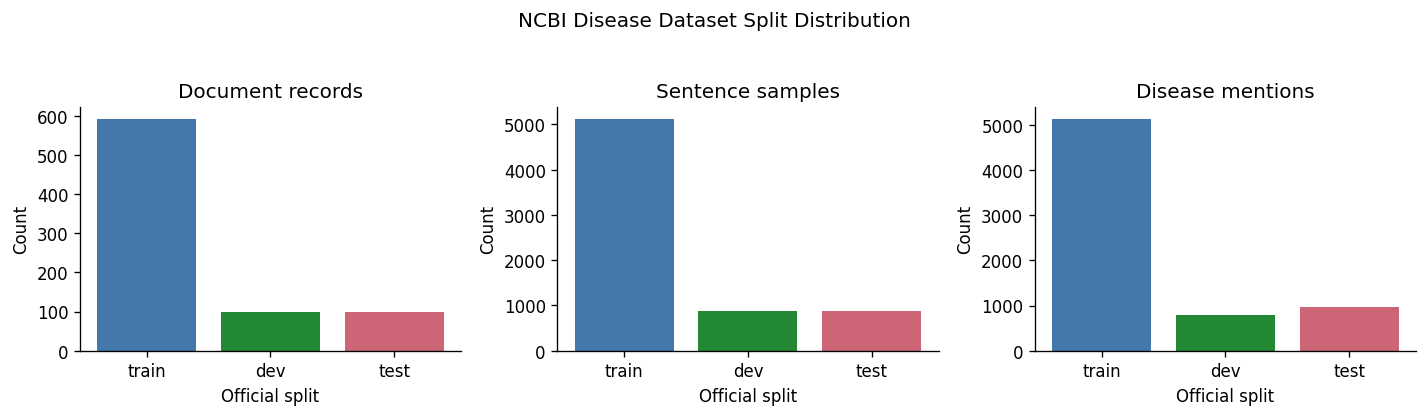

In [16]:
def save_table(frame, path, index=True):
    if not Path(path).exists():
        frame.to_csv(path, index=index)

def save_figure(fig, path):
    if not Path(path).exists():
        fig.savefig(path, bbox_inches='tight')

from collections import Counter
statistics = []
for split, rows in datasets.items():
    lengths = np.array([len(r['tokens']) for r in rows])
    counts = Counter(t for r in rows for t in r['ner_tags'])
    statistics.append({'split':split, 'document_records':len(documents[split]),
        'unique_pmids':len({d['pmid'] for d in documents[split]}), 'sentence_samples':len(rows),
        'tokens':int(lengths.sum()), 'disease_mentions':sum(len(r['entities']) for r in rows),
        'mean_sentence_tokens':lengths.mean(), 'median_sentence_tokens':np.median(lengths),
        'max_sentence_tokens':int(lengths.max()), **{label:counts[label] for label in LABELS}})
stats = pd.DataFrame(statistics).set_index('split')
save_table(stats, ROOT / 'results/eda/dataset_statistics.csv')
display(stats.round(2))
colors = ['#4477AA','#228833','#CC6677']
def save_eda(fig, name):
    fig.tight_layout()
    save_figure(fig, ROOT / 'results/eda' / name)
    plt.show()
fig, axes = plt.subplots(1, 3, figsize=(12,3.3))
for ax, column, title in zip(axes, ['document_records','sentence_samples','disease_mentions'],
                            ['Document records','Sentence samples','Disease mentions']):
    ax.bar(stats.index, stats[column], color=colors)
    ax.set(title=title, xlabel='Official split', ylabel='Count')
fig.suptitle('NCBI Disease Dataset Split Distribution', y=1.04)
save_eda(fig, 'split_distribution.png')

Dev and Test each contain 100 records, while Train is substantially larger. Sentence and mention counts differ because a sentence can contain several entities or none.

### 4.2 BIO labels and source categories

BIO frequencies count tokens; source categories describe disease mentions.

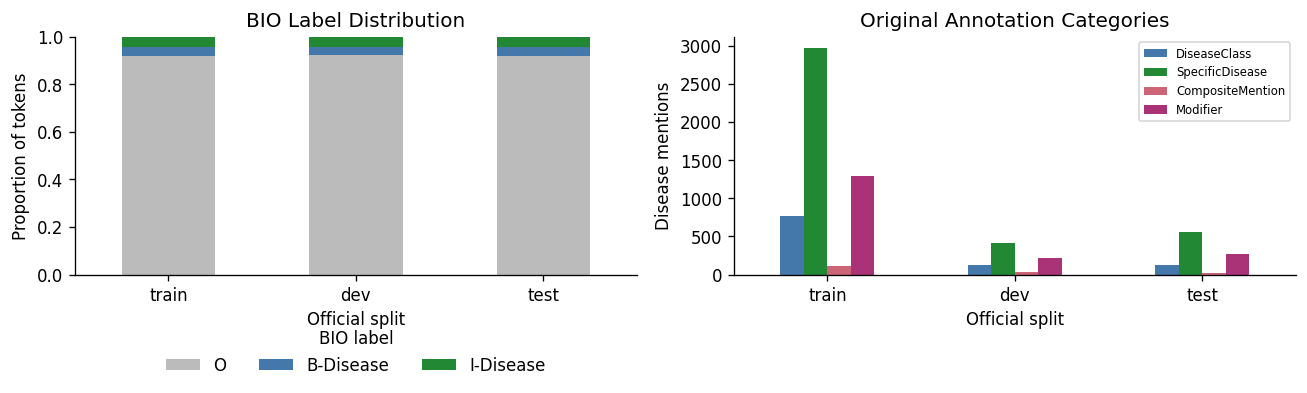

**Observed:** 91.7% of Train tokens are O. Token accuracy would therefore exaggerate recognition quality. Exact entity F1 is the primary metric; we retain standard cross-entropy for the controlled baseline rather than tuning class weights.

In [17]:
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
proportions = stats[LABELS].div(stats['tokens'], axis=0)
proportions.plot.bar(stacked=True, ax=axes[0], color=['#BBBBBB','#4477AA','#228833'], rot=0)
axes[0].set(title='BIO Label Distribution', xlabel='Official split', ylabel='Proportion of tokens', ylim=(0,1))
axes[0].legend(title='BIO label', loc='upper center', bbox_to_anchor=(0.5,-0.17), ncol=3, frameon=False)
category_counts = pd.DataFrame({s:Counter(a['source_category'] for d in docs for a in d['annotations'])
                                for s,docs in documents.items()}).T.fillna(0)
category_counts.plot.bar(ax=axes[1], rot=0, color=['#4477AA','#228833','#CC6677','#AA3377'])
axes[1].set(title='Original Annotation Categories', xlabel='Official split', ylabel='Disease mentions')
axes[1].legend(fontsize=7)
save_eda(fig, 'label_distribution.png')
save_table(category_counts, ROOT / 'results/eda/source_category_counts.csv')
display(Markdown(f"**Observed:** {100*proportions.loc['train','O']:.1f}% of Train tokens are O. "
    'Token accuracy would therefore exaggerate recognition quality. Exact entity F1 is the primary metric; '
    'we retain standard cross-entropy for the controlled baseline rather than tuning class weights.'))

### 4.3 Sentence lengths

Lengths use model-independent regex tokens; WordPiece lengths are measured during encoding.

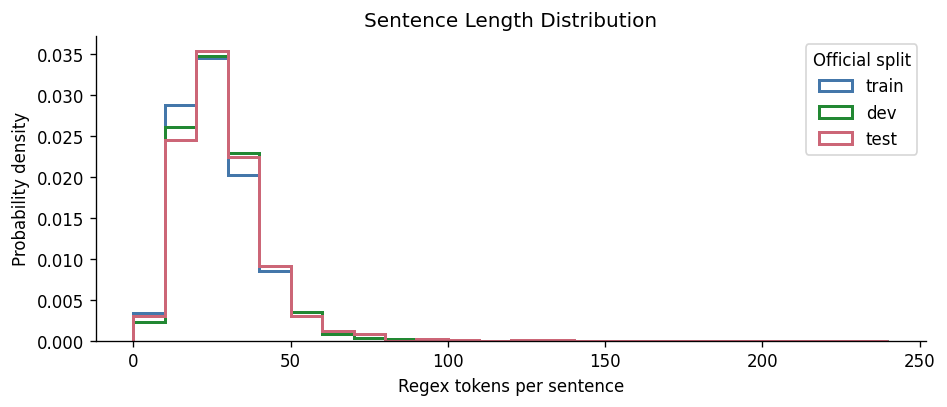

**Observed:** Train has median 24 tokens and maximum 224. The long tail makes silent truncation unsafe. Our pipeline splits long inputs into word-aligned chunks, retains every token, and reconstructs the complete original sentence before entity evaluation.

In [18]:
fig, ax = plt.subplots(figsize=(8,3.5))
bins = np.arange(0, 241, 10)
for color, (split, rows) in zip(colors, datasets.items()):
    values = [len(r['tokens']) for r in rows]
    ax.hist(values, bins=bins, density=True, histtype='step', linewidth=1.8, label=split, color=color)
ax.set(title='Sentence Length Distribution', xlabel='Regex tokens per sentence', ylabel='Probability density')
ax.legend(title='Official split')
save_eda(fig, 'sentence_lengths.png')
display(Markdown(f"**Observed:** Train has median {stats.loc['train','median_sentence_tokens']:.0f} "
    f"tokens and maximum {stats.loc['train','max_sentence_tokens']:.0f}. The long tail makes silent "
    'truncation unsafe. Our pipeline splits long inputs into word-aligned chunks, retains every token, '
    'and reconstructs the complete original sentence before entity evaluation.'))

### 4.4 Entity length and density

Entity length counts tokens within a mention, including punctuation. Density measures mentions per 100 tokens.

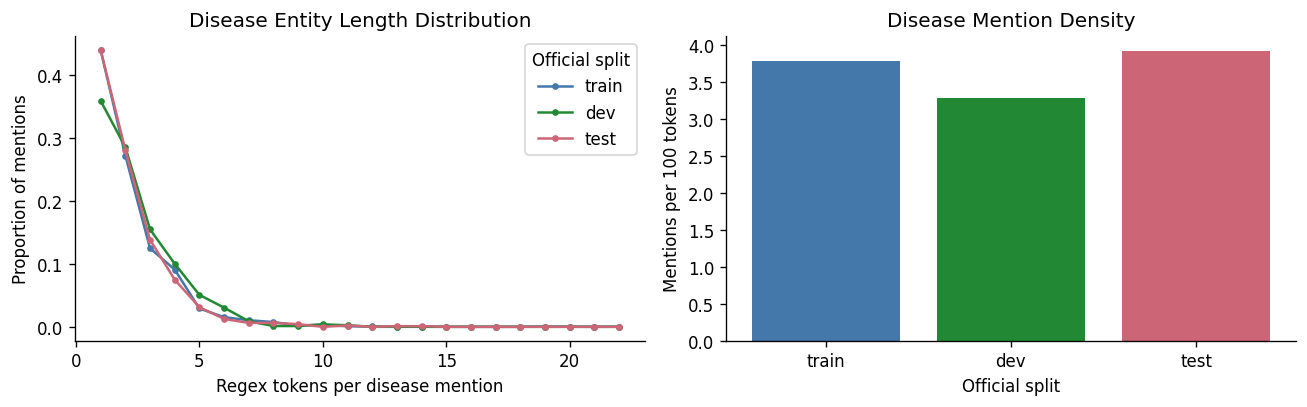

,mean_tokens,max_tokens,multi_token_percent
train,2.19,22.0,55.96
dev,2.39,11.0,64.04
test,2.13,14.0,55.94


**Observed:** 56.0% of Train mentions span multiple tokens. Correct disease classification alone is insufficient: a one-token boundary error counts as an incorrect entity. The Train/Dev difference in entity lengths also warrants caution when interpreting a single validation score.

In [19]:
entity_lengths = {s:[e['token_end']-e['token_start'] for r in rows for e in r['entities']]
                  for s,rows in datasets.items()}
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
maximum = max(max(v) for v in entity_lengths.values())
for color, (split, values) in zip(colors, entity_lengths.items()):
    counts = Counter(values)
    axes[0].plot(range(1,maximum+1), [counts[n]/len(values) for n in range(1,maximum+1)],
                 marker='.', label=split, color=color)
axes[0].set(title='Disease Entity Length Distribution', xlabel='Regex tokens per disease mention',
            ylabel='Proportion of mentions')
axes[0].legend(title='Official split')
density = 100*stats['disease_mentions']/stats['tokens']
axes[1].bar(density.index, density, color=colors)
axes[1].set(title='Disease Mention Density', xlabel='Official split', ylabel='Mentions per 100 tokens')
save_eda(fig, 'entity_lengths_and_density.png')
length_table = pd.DataFrame({s:{'mean_tokens':np.mean(v), 'max_tokens':max(v),
    'multi_token_percent':100*np.mean(np.array(v)>1)} for s,v in entity_lengths.items()}).T
save_table(length_table, ROOT / 'results/eda/entity_length_statistics.csv')
display(length_table.round(2))
display(Markdown(f"**Observed:** {length_table.loc['train','multi_token_percent']:.1f}% of Train mentions "
    'span multiple tokens. Correct disease classification alone is insufficient: a one-token boundary '
    'error counts as an incorrect entity. The Train/Dev difference in entity lengths also warrants '
    'caution when interpreting a single validation score.'))

### 4.5 Data characteristics and challenges

An uppercase-surface heuristic identifies possible abbreviations. Frequent names and long-mention examples are drawn from Train.

In [20]:
import re
train_entities = [e for r in datasets['train'] for e in r['entities']]
short_upper = [e for e in train_entities if re.fullmatch(r'[A-Z][A-Z0-9-]{1,9}',e['text'])]
common = Counter(e['text'].lower() for e in train_entities).most_common(10)
display(pd.DataFrame(common, columns=['Train disease surface (lowercased for counting only)','Frequency']))
display(pd.DataFrame(sorted(train_entities, key=lambda e:e['token_end']-e['token_start'], reverse=True)[:5])[
    ['text','source_category','token_start','token_end']])
display(Markdown(f"**Medical vocabulary and abbreviations.** Train contains {len(short_upper)} "
    f"short uppercase mentions ({100*len(short_upper)/len(train_entities):.1f}%); examples are "
    + ', '.join(dict.fromkeys(e['text'] for e in short_upper[:12])) + '. Case is retained. '
    'Long compositional names and frequent short forms motivate contextual encoders and the subword audit below.'))

,Train disease surface (lowercased for counting only),Frequency
0,dm,120
1,dmd,109
2,apc,91
3,ald,86
4,pws,75
5,myotonic dystrophy,71
6,was,63
7,g6pd deficiency,57
8,hd,55
9,aniridia,53


,text,source_category,token_start,token_end
0,Glucose-6-phosphate dehydrogenase (G6PD; E. C....,SpecificDisease,0,22
1,Glucose-6-phosphate dehydrogenase (G6PD; EC 1....,Modifier,0,20
2,Glucose-6-phosphate dehydrogenase (G6PD; EC 1....,SpecificDisease,0,19
3,Glucose-6-PHOSPHATE dehydrogenase (G6PD; EC 1....,SpecificDisease,0,19
4,"rare, sex-linked recessive, dysmyelinating dis...",DiseaseClass,6,20


**Medical vocabulary and abbreviations.** Train contains 1532 short uppercase mentions (29.8%); examples are APC, HH, FMF. Case is retained. Long compositional names and frequent short forms motivate contextual encoders and the subword audit below.

Modifiers and composite mentions require consistent boundaries around hyphens, parentheses and coordinated disease names. These research abstracts provide limited evidence about transfer to clinical notes or other biomedical domains.

## 5. Shared NER Training Pipeline
### 5.1 Model choice and token classification

[BERT-base-cased](https://huggingface.co/google-bert/bert-base-cased) provides a general-domain baseline. [BioBERT v1.1](https://huggingface.co/dmis-lab/biobert-base-cased-v1.1) adds PubMed pretraining to the same base architecture, motivating a controlled comparison of pretrained representations.

Each encoder receives a new linear head with three BIO outputs. All parameters are fine-tuned with cross-entropy loss.

The architectures and pretrained weights come from their original authors; PyTorch, Hugging Face and seqeval provide modelling, training and evaluation primitives. Our work covers corpus conversion, alignment, chunk reconstruction and experiment design. First-subword supervision follows the [Hugging Face task guide](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/token_classification).

### 5.2 Shared configuration

Pretrained revisions and experiment settings are specified below.

In [21]:
MODEL_CONFIGS = {'bert_base':'bert-base-cased', 'biobert':'dmis-lab/biobert-base-cased-v1.1',
    'pubmedbert':'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract',
    'scibert':'allenai/scibert_scivocab_cased'}
MODEL_REVISIONS = {'bert_base': 'cd5ef92a9fb2f889e972770a36d4ed042daf221e',
 'biobert': '924f12e0c3db7f156a765ad53fb6b11e7afedbc8',
 'pubmedbert': 'd673b8835373c6fa116d6d8006b33d48734e305d',
 'scibert': 'ddf0be025f8e432a1870e34811997ba6725bf04a'}
CONFIG = {'learning_rate':2e-5, 'batch_size':8, 'gradient_accumulation_steps':2,
          'num_train_epochs':3, 'max_length':128, 'weight_decay':0.01,
          'warmup_ratio':0.1, 'seed':42, 'fp16':True}
display(pd.Series(CONFIG, name='Experiment configuration').to_frame())
print('Effective training batch:', CONFIG['batch_size']*CONFIG['gradient_accumulation_steps'])

NEW_MODEL_KEYS = {'pubmedbert','scibert'}
INITIAL_RUNS = {'bert_base':'baseline','biobert':'initial','pubmedbert':'baseline','scibert':'baseline'}
TOKENIZER_OPTIONS = {key:{'do_lower_case':key == 'pubmedbert'} for key in MODEL_CONFIGS}


def experiment_directory(root, model_key, run_name, folder='models'):
    directory = Path(root)/folder/model_key
    if model_key == 'biobert' and run_name in {'lr3e5','extended5'}:
        return directory/'tuning'/run_name
    return directory/('baseline' if model_key == 'biobert' and run_name == 'initial' else run_name)

def should_train(model_key):
    complete = ((experiment_directory(ROOT,model_key,INITIAL_RUNS[model_key],'results')/'validation_metrics.json').is_file()
                and (experiment_directory(ROOT,model_key,INITIAL_RUNS[model_key])/'best/model.safetensors').is_file())
    return RETRAIN or (TRAIN_NEW_MODELS and model_key in NEW_MODEL_KEYS and not complete)


,Experiment configuration
learning_rate,0.00002
batch_size,8
gradient_accumulation_steps,2
num_train_epochs,3
max_length,128
weight_decay,0.01
warmup_ratio,0.1
seed,42
fp16,True


Effective training batch: 16


### 5.3 Training budget

Initial models share the data, seed 42, three-epoch budget and effective batch size **16** (8 × 2 accumulated microbatches). AdamW uses a linear schedule with 10% warmup and gradient clipping at norm 1.0; FP16 and padding to multiples of eight fit the 8 GiB GPU.

No class weighting or augmentation is applied. Logged gradient norms precede clipping; only epoch-end diagnostics were retained, limiting analysis of individual AMP scaler events.

### 5.4 Pretrained weights

Repository revisions and weight hashes identify each pretrained initialization.

In [22]:
def fetch_pretrained(root, model_key):
    directory = Path(root) / "models" / model_key / "pretrained"
    marker = directory / "source_revision.json"
    if marker.exists():
        record = json.loads(marker.read_text())
        assert record['revision'] == MODEL_REVISIONS[model_key]
        assert sha256(directory / record['weight_file']) == record['weight_sha256']
        assert (directory / 'config.json').exists() and (directory / 'vocab.txt').exists()
        return directory, record
    repository = MODEL_CONFIGS[model_key]
    info = HfApi().model_info(repository, revision=MODEL_REVISIONS[model_key])
    available = {file.rfilename for file in info.siblings}
    weight = "model.safetensors" if "model.safetensors" in available else "pytorch_model.bin"
    assert weight in available
    patterns = [weight, "config.json", "vocab.txt", "tokenizer.json", "tokenizer_config.json",
                "special_tokens_map.json"]
    snapshot_download(repository, revision=info.sha, local_dir=directory,
                      allow_patterns=patterns, max_workers=2)
    source_config = json.loads((directory / "config.json").read_text())
    assert not any("TokenClassification" in name for name in source_config.get("architectures", []))
    record = {"requested_repository": repository, "resolved_repository": info.id,
        "revision": info.sha, "weight_file": weight, "weight_sha256": sha256(directory / weight),
        "retrieved_utc": datetime.now(timezone.utc).isoformat(), "source_config": source_config,
        "purpose": "pretrained encoder; not an NCBI Disease fine-tuned checkpoint"}
    write_json(marker, record)
    return directory, record

In [23]:
def resolve_checkpoint(root, model_key, run_name):
    path = experiment_directory(root, model_key, run_name)/'best'
    if (path/'model.safetensors').is_file() and (path/'config.json').is_file():
        return path
    raise FileNotFoundError(f'No checkpoint at {path}. Restore its weights and tokenizer, '
        'or set RETRAIN=True to train from pretrained weights. No training was started.')

pretrained, model_sources, tokenizers = {}, {}, {}
for key in MODEL_CONFIGS:
    if should_train(key):
        pretrained[key], model_sources[key] = fetch_pretrained(ROOT, key)
        tokenizer_path = pretrained[key]
    else:
        run = INITIAL_RUNS[key]
        tokenizer_path = resolve_checkpoint(ROOT, key, run)
    tokenizers[key] = AutoTokenizer.from_pretrained(tokenizer_path, use_fast=True,
                                                    **TOKENIZER_OPTIONS[key], local_files_only=True)
    assert tokenizers[key].is_fast and tokenizers[key].do_lower_case == TOKENIZER_OPTIONS[key]['do_lower_case']
display(pd.DataFrame([{'model':k,'tokenizer':'pretrained' if should_train(k) else 'saved checkpoint',
    'pretrained_revision':MODEL_REVISIONS[k]} for k in MODEL_CONFIGS]))

,model,tokenizer,pretrained_revision
0,bert_base,saved checkpoint,cd5ef92a9fb2f889e972770a36d4ed042daf221e
1,biobert,saved checkpoint,924f12e0c3db7f156a765ad53fb6b11e7afedbc8
2,pubmedbert,saved checkpoint,d673b8835373c6fa116d6d8006b33d48734e305d
3,scibert,saved checkpoint,ddf0be025f8e432a1870e34811997ba6725bf04a


### 5.5 Subword alignment and long inputs

Each model uses its corresponding `AutoTokenizer`; `word_ids()` links WordPiece subtokens to original tokens. Only the first subword receives the BIO label; subsequent subwords, special tokens and padding receive `-100` and do not contribute to loss.

Inputs exceeding 128 subwords are split into non-overlapping, whole-token chunks determined by input length. Every token appears once, and predictions are rejoined before sentence-level evaluation. Entities may cross a chunk boundary, with reduced context but no discarded tokens.

In [24]:
def encode_samples(samples, tokenizer, max_length=128):
    """Chunk at whole-word boundaries; every original token is supervised once."""
    features, mappings, full_lengths = [], [], []
    cut_inside_entity = 0
    budget = max_length - tokenizer.num_special_tokens_to_add(pair=False)
    for sample_index, sample in enumerate(samples):
        raw = tokenizer(sample["tokens"], is_split_into_words=True, add_special_tokens=False,
                        truncation=False, return_attention_mask=False, return_token_type_ids=False)
        words = raw.word_ids()
        sizes = np.bincount(words, minlength=len(sample["tokens"]))
        assert len(sizes) == len(sample["tokens"]) and np.all(sizes > 0)
        assert max(sizes) <= budget, "A single token exceeds the subword budget."
        full_lengths.append(len(raw["input_ids"]) + tokenizer.num_special_tokens_to_add(False))
        start = 0
        while start < len(sizes):
            end, used = start, 0
            while end < len(sizes) and used + sizes[end] <= budget:
                used += sizes[end]
                end += 1
            encoded = tokenizer(sample["tokens"][start:end], is_split_into_words=True,
                                truncation=False)
            assert len(encoded["input_ids"]) <= max_length
            previous = None
            labels, positions, word_indices = [], [], []
            for position, word in enumerate(encoded.word_ids()):
                if word is not None and word != previous:
                    labels.append(label2id[sample["ner_tags"][start + word]])
                    positions.append(position)
                    word_indices.append(start + word)
                else:
                    labels.append(-100)
                previous = word
            assert word_indices == list(range(start, end))
            features.append({**dict(encoded), "labels": labels})
            mappings.append({"sample_index": sample_index, "word_indices": word_indices,
                             "positions": positions})
            if end < len(sizes) and sample["ner_tags"][end] == "I-Disease":
                cut_inside_entity += 1
            start = end
    assert sum(len(m["word_indices"]) for m in mappings) == sum(len(s["tokens"]) for s in samples)
    audit = {"sentence_samples": len(samples), "encoded_chunks": len(features),
        "sentences_over_max_length": sum(n > max_length for n in full_lengths),
        "max_sentence_subwords_with_specials": max(full_lengths),
        "mean_sentence_subwords_with_specials": float(np.mean(full_lengths)),
        "entity_crossing_chunk_boundaries": cut_inside_entity,
        "original_tokens": sum(len(s["tokens"]) for s in samples), "dropped_tokens": 0}
    return features, mappings, audit

### 5.6 Word-level decoding

Restore chunk predictions to the original sentence tokens before entity scoring.

In [25]:
def decode_predictions(logits, mappings, samples):
    predictions = [[None] * len(sample["tokens"]) for sample in samples]
    ids = np.argmax(logits, axis=-1)
    assert len(ids) == len(mappings)
    for row, mapping in zip(ids, mappings):
        for position, word in zip(mapping["positions"], mapping["word_indices"]):
            target = predictions[mapping["sample_index"]]
            assert target[word] is None
            target[word] = id2label[int(row[position])]
    assert all(all(tag is not None for tag in row) for row in predictions)
    return predictions

def entity_metrics(gold, predicted):
    assert len(gold) == len(predicted) and all(len(a) == len(b) for a, b in zip(gold, predicted))
    kwargs = {"mode": "strict", "scheme": IOB2, "zero_division": 0}
    return {"precision": float(precision_score(gold, predicted, **kwargs)),
            "recall": float(recall_score(gold, predicted, **kwargs)),
            "f1": float(f1_score(gold, predicted, **kwargs))}

In [26]:
def metric_function(mappings, samples):
    gold = [s["ner_tags"] for s in samples]
    def compute(evaluation):
        predicted = decode_predictions(evaluation.predictions, mappings, samples)
        # Padding, special tokens, and non-first subwords are never decoded.
        return entity_metrics(gold, predicted)
    return compute

def load_model(directory):
    return AutoModelForTokenClassification.from_pretrained(directory, num_labels=len(LABELS),
        id2label=id2label, label2id=label2id, attn_implementation="sdpa")

In [27]:
alignment_sample = next(r for r in datasets['train'] if any(e['token_end']-e['token_start']>=4 for e in r['entities']))
alignment = tokenizers['biobert'](alignment_sample['tokens'], is_split_into_words=True, truncation=False)
aligned_labels, previous = [], None
for word in alignment.word_ids():
    aligned_labels.append(alignment_sample['ner_tags'][word] if word is not None and word != previous else -100)
    previous = word
display(pd.DataFrame({'WordPiece':tokenizers['biobert'].convert_ids_to_tokens(alignment['input_ids']),
    'original_word_index':alignment.word_ids(), 'loss_label':aligned_labels}))
audits = []
for key, tokenizer in tokenizers.items():
    for split, samples in datasets.items():
        _, _, audit = encode_samples(samples, tokenizer, CONFIG['max_length'])
        audits.append({'model':key, 'split':split, **audit})
tokenization_audit = pd.DataFrame(audits)
save_table(tokenization_audit, ROOT / 'results/comparison/four_model_tokenization_audit.csv', index=False)
display(tokenization_audit)

,WordPiece,original_word_index,loss_label
0,[CLS],NaN,-100
1,Most,0.0,O
2,co,1.0,B-Disease
3,##lon,1.0,-100
4,cancer,2.0,I-Disease
...,...,...,...
66,##ili,45.0,-100
67,##zing,45.0,-100
68,mutations,46.0,O
69,.,47.0,O


,model,split,sentence_samples,encoded_chunks,sentences_over_max_length,max_sentence_subwords_with_specials,mean_sentence_subwords_with_specials,entity_crossing_chunk_boundaries,original_tokens,dropped_tokens
0,bert_base,train,5129,5139,9,278,37.982063,0,136086,0
1,bert_base,dev,882,882,0,123,38.430839,0,23969,0
2,bert_base,test,885,890,5,158,39.392090,0,24495,0
3,biobert,train,5129,5139,9,278,37.982063,0,136086,0
4,biobert,dev,882,882,0,123,38.430839,0,23969,0
5,biobert,test,885,890,5,158,39.392090,0,24495,0
6,pubmedbert,train,5129,5135,5,278,30.806980,0,136086,0
7,pubmedbert,dev,882,882,0,106,31.106576,0,23969,0
8,pubmedbert,test,885,888,3,140,32.085876,0,24495,0
9,scibert,train,5129,5135,5,270,32.741470,0,136086,0


### 5.7 Checkpoint inference

Saved models run in evaluation mode with batch size 8 and FP16 on CUDA. CPU inference uses FP32, so bitwise agreement across hardware is not assumed.

In [28]:
def evaluate_checkpoint(checkpoint, samples, config):
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, use_fast=True, local_files_only=True)
    model = AutoModelForTokenClassification.from_pretrained(checkpoint, local_files_only=True,
                attn_implementation='sdpa').to('cuda' if torch.cuda.is_available() else 'cpu').eval()
    assert model.config.label2id == label2id and model.config.id2label == id2label
    features, mappings, audit = encode_samples(samples, tokenizer, config['max_length'])
    loader = DataLoader(features, batch_size=config['batch_size'], shuffle=False, num_workers=0,
        collate_fn=DataCollatorForTokenClassification(tokenizer, pad_to_multiple_of=8))
    batches, loss_sum, chunk_count = [], 0.0, 0
    with torch.inference_mode(), torch.autocast(device_type=model.device.type,
            dtype=torch.float16, enabled=config['fp16'] and model.device.type == 'cuda'):
        for batch in loader:
            batch = {k:v.to(model.device) for k,v in batch.items()}
            output = model(**batch)
            assert torch.isfinite(output.loss) and torch.isfinite(output.logits).all()
            logits = output.logits.float().cpu().numpy()
            for row in logits:
                padded = np.zeros((config['max_length'], len(LABELS)), dtype=np.float32)
                padded[:len(row)] = row
                batches.append(padded)
            loss_sum += output.loss.item()*len(logits)
            chunk_count += len(logits)
    predicted = decode_predictions(np.stack(batches), mappings, samples)
    metrics = entity_metrics([s['ner_tags'] for s in samples], predicted)
    metrics['validation_loss'] = loss_sum/chunk_count
    assert audit['dropped_tokens'] == 0
    del model, loader, batch, output
    gc.collect()
    torch.cuda.empty_cache()
    return metrics, predicted

### 5.8 Reproduction checks

Fresh predictions and data hashes are compared with saved experiments; training histories supply the epoch-level curves.

In [29]:
def reproduce_experiment(root, model_key, run_name, config, datasets):
    root = Path(root)
    directory = experiment_directory(root, model_key, run_name, 'results')
    required = ['training_config.json','training_history.csv','validation_metrics.json','predictions.jsonl']
    missing = [name for name in required if not (directory/name).exists()]
    if missing:
        raise FileNotFoundError(f'Missing experiment records for {model_key}/{run_name}: {missing}. '
            'Restore the experiment or set RETRAIN=True. No training was started.')
    checkpoint = resolve_checkpoint(root, model_key, run_name)
    recorded = json.loads((directory/'training_config.json').read_text())
    saved = json.loads((directory/'validation_metrics.json').read_text())
    assert recorded['signature']['hyperparameters'] == config
    assert recorded['signature']['pretrained_revision'] == MODEL_REVISIONS[model_key]
    for split, digest in recorded['signature']['data_sha256'].items():
        assert sha256(root/'data/processed'/f'{split}.jsonl') == digest
    assert recorded['signature']['model_key'] == model_key and recorded['signature']['run_name'] == run_name
    assert root/saved['best_checkpoint'] == checkpoint and root/saved['result_directory'] == directory
    assert sha256(checkpoint/'model.safetensors') == saved['checkpoint_sha256']
    fresh, predicted = evaluate_checkpoint(checkpoint, datasets['dev'], config)
    assert all(abs(fresh[k]-saved[k]) < 1e-12 for k in ['precision','recall','f1'])
    assert abs(fresh['validation_loss']-saved['validation_loss']) < 1e-6
    exports = read_jsonl(directory/'predictions.jsonl')
    assert len(exports) == len(datasets['dev']) == len(predicted)
    for old_row, sample, labels in zip(exports, datasets['dev'], predicted):
        assert old_row['sample_id'] == sample['id'] and old_row['tokens'] == sample['tokens']
        assert old_row['gold_labels'] == sample['ner_tags'] and old_row['predicted_labels'] == labels
    history = pd.read_csv(directory/'training_history.csv')
    assert history.loc[history.f1.idxmax(),'epoch'] == saved['best_epoch']
    metrics = {**saved, **fresh, 'best_checkpoint':checkpoint.relative_to(root).as_posix(),
        'inference_verified':True,
        'inference_checkpoint':checkpoint.relative_to(root).as_posix(),
        'result_directory':directory.relative_to(root).as_posix()}
    print(f'Fresh Dev inference verified: {model_key}/{run_name} ({len(predicted)} sentences).')
    return metrics, history, predicted

### 5.9 Optimization and training history

In [30]:
def make_training_arguments(model_output, config):
    return TrainingArguments(output_dir=str(model_output / 'checkpoints'),
        learning_rate=config['learning_rate'], num_train_epochs=config['num_train_epochs'],
        per_device_train_batch_size=config['batch_size'], per_device_eval_batch_size=config['batch_size'],
        gradient_accumulation_steps=config['gradient_accumulation_steps'],
        weight_decay=config['weight_decay'], warmup_ratio=config['warmup_ratio'],
        lr_scheduler_type='linear', optim='adamw_torch', max_grad_norm=1.0,
        eval_strategy='epoch', save_strategy='epoch', logging_strategy='epoch',
        metric_for_best_model='f1', greater_is_better=True, load_best_model_at_end=True,
        save_total_limit=1, save_only_model=True, seed=config['seed'], data_seed=config['seed'],
        fp16=config['fp16'], report_to=[], disable_tqdm=True, dataloader_num_workers=0,
        dataloader_pin_memory=True, full_determinism=False)

In [31]:
def describe_training(signature, source, args):
    return {"signature":signature, "model_source":source,
        "python_executable": __import__('sys').executable,
        "torch":torch.__version__, "transformers":transformers.__version__,
        "gpu":torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
        "started_utc":datetime.now(timezone.utc).isoformat(),
        "optimizer":"torch AdamW", "scheduler":"linear with warmup",
        "selection":"maximum Dev strict IOB2 entity F1; earliest epoch on ties",
        "subword_policy":"first subword only; remaining/special/padding labels=-100",
        "long_sentence_policy":"non-overlapping whole-word chunks; full-sentence reconstruction",
        "test_policy":"not evaluated or used for selection", "training_arguments":args.to_dict()}

In [32]:
def record_training_history(trainer, output):
    write_json(output / 'trainer_log.json', trainer.state.log_history)
    epoch_rows = []
    for log in trainer.state.log_history:
        if 'eval_f1' in log:
            training_log = next(x for x in trainer.state.log_history
                                if 'loss' in x and abs(x['epoch']-log['epoch']) < 1e-5)
            epoch_rows.append({'epoch':log['epoch'], 'training_loss':training_log['loss'],
                'validation_loss':log['eval_loss'], 'precision':log['eval_precision'],
                'recall':log['eval_recall'], 'f1':log['eval_f1']})
    history = pd.DataFrame(epoch_rows)
    history.to_csv(output / 'training_history.csv', index=False)
    return history

### 5.10 Checkpoint and prediction export

Save the selected model and original-token Dev predictions, then compare weights and logits after reloading.

In [33]:
def verify_saved_checkpoint(trainer, directory, features, config):
    restored = AutoModelForTokenClassification.from_pretrained(directory,
                attn_implementation='sdpa').to(trainer.model.device).eval()
    batch = trainer.data_collator(features[:2])
    batch = {k:v.to(trainer.model.device) for k,v in batch.items() if k != 'labels'}
    trainer.model.eval()
    assert all(torch.equal(value, restored.state_dict()[name])
               for name,value in trainer.model.state_dict().items())
    with torch.no_grad(), torch.autocast(device_type=trainer.model.device.type,
            dtype=torch.float16, enabled=config['fp16']):
        before, after = trainer.model(**batch).logits, restored(**batch).logits
    assert torch.allclose(before.float(), after.float(), atol=1e-6, rtol=1e-5)
    del restored, before, after, batch

def export_predictions(path, samples, predicted, metrics, source):
    write_jsonl(path, [{'sample_id':sample['id'], 'document_id':sample['document_id'],
        'pmid':sample['pmid'], 'split':'dev', 'tokens':sample['tokens'],
        'gold_labels':sample['ner_tags'], 'predicted_labels':tags,
        'token_offsets':sample['token_offsets'], 'gold_entities':sample['entities'],
        'model':metrics['model'], 'run_name':metrics['run_name'],
        'pretrained_revision':source['revision'], 'checkpoint_sha256':metrics['checkpoint_sha256']}
        for sample,tags in zip(samples,predicted)])

In [34]:
def finalize_training(trainer, root, model_key, run_name, output, model_output,
                      source, datasets, encoded, config, duration):
    history = record_training_history(trainer, output)
    best_row = history.loc[history.f1.idxmax()].to_dict()
    selected_checkpoint = Path(trainer.state.best_model_checkpoint).name
    trainer.save_model(str(model_output/'best'))
    trainer.processing_class.save_pretrained(model_output/'best')
    prediction = trainer.predict(encoded['dev'][0])
    predicted = decode_predictions(prediction.predictions, encoded['dev'][1], datasets['dev'])
    metrics = {**entity_metrics([r['ner_tags'] for r in datasets['dev']], predicted),
        'validation_loss':float(prediction.metrics['test_loss']), 'split':'dev',
        'model':MODEL_CONFIGS[model_key], 'run_name':run_name, 'best_epoch':best_row['epoch'],
        'selected_trainer_checkpoint':selected_checkpoint,
        'best_checkpoint':(model_output/'best').relative_to(root).as_posix(),
        'checkpoint_sha256':sha256(model_output/'best/model.safetensors'),
        'training_seconds':duration, 'number_of_sentences':len(datasets['dev']),
        'number_of_gold_entities':sum(len(r['entities']) for r in datasets['dev']),
        'completed_utc':datetime.now(timezone.utc).isoformat(),
        'result_directory':output.relative_to(root).as_posix()}
    assert abs(metrics['f1']-best_row['f1']) < 1e-12
    export_predictions(output/'predictions.jsonl', datasets['dev'], predicted, metrics, source)
    verify_saved_checkpoint(trainer, model_output/'best', encoded['dev'][0], config)
    metrics['checkpoint_reload_verified'] = True
    write_json(output/'validation_metrics.json', metrics)
    temporary = (model_output/'checkpoints').resolve()
    assert temporary.is_relative_to((root/'models').resolve())
    if temporary.exists(): shutil.rmtree(temporary)
    return metrics, history, predicted

### 5.11 Experiment execution

In [35]:
def run_experiment(root, model_key, run_name, config, datasets, retrain=False):
    root = Path(root)
    if not retrain:
        return reproduce_experiment(root, model_key, run_name, config, datasets)
    if config['fp16'] and not torch.cuda.is_available():
        raise RuntimeError('The original FP16 training configuration requires CUDA. No training was started.')
    pretrained_path, source = fetch_pretrained(root, model_key)
    canonical = experiment_directory(root, model_key, run_name)
    first_baseline = model_key in NEW_MODEL_KEYS and not canonical.exists()
    storage_name = canonical.name if first_baseline else f'{canonical.name}_{RUN_TAG}'
    output = experiment_directory(root,model_key,run_name,'results').with_name(storage_name)
    model_output = canonical.with_name(storage_name)
    if output.exists() or model_output.exists():
        raise FileExistsError('This new run already exists. Restart with a new RUN_TAG; no artifacts were overwritten.')
    output.mkdir(parents=True)
    model_output.mkdir(parents=True)
    set_seed(config['seed'])
    tokenizer = AutoTokenizer.from_pretrained(pretrained_path, use_fast=True, **TOKENIZER_OPTIONS[model_key])
    encoded = {s:encode_samples(datasets[s], tokenizer, config['max_length']) for s in ['train','dev']}
    write_json(output/'tokenization_audit.json', {s:parts[2] for s,parts in encoded.items()})
    model = load_model(pretrained_path)
    args = make_training_arguments(model_output, config)
    signature = {'model_key':model_key, 'run_name':run_name, 'hyperparameters':config,
        'data_sha256':{s:sha256(root/'data/processed'/f'{s}.jsonl') for s in ['train','dev']},
        'pretrained_revision':source['revision']}
    record = describe_training(signature, source, args)
    record['tokenizer_options'] = TOKENIZER_OPTIONS[model_key]
    write_json(output/'training_config.json', record)
    trainer = Trainer(model=model, args=args, train_dataset=encoded['train'][0],
        eval_dataset=encoded['dev'][0], processing_class=tokenizer,
        data_collator=DataCollatorForTokenClassification(tokenizer, pad_to_multiple_of=8),
        compute_metrics=metric_function(encoded['dev'][1], datasets['dev']))
    start = time.perf_counter()
    trainer.train()
    result = finalize_training(trainer, root, model_key, run_name, output, model_output,
        source, datasets, encoded, config, time.perf_counter()-start)
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return result

### 5.12 Metrics and checkpoint selection

The primary metric is **Dev strict IOB2 entity F1**, calculated with seqeval on complete original-token sequences. An entity must match in type and both boundaries; illegal `I` transitions are not repaired.

Precision divides correct entities by predicted entities, recall divides them by gold entities, and F1 is their harmonic mean. Select the highest Dev F1, choosing the earliest epoch on ties; Test is not used for training or model selection.

### 5.13 Smoke tests

Small fixtures check label restoration and entity metrics. Training mode also checks forward and backward passes before reloading fresh pretrained weights.

In [36]:
def smoke_test(directory, tokenizer, samples, max_length=128):
    set_seed(42)
    model = load_model(directory).to("cuda" if torch.cuda.is_available() else "cpu")
    features, mapping, audit = encode_samples(samples, tokenizer, max_length)
    batch = DataCollatorForTokenClassification(tokenizer)(features)
    batch = {k:v.to(model.device) for k,v in batch.items()}
    output = model(**batch)
    assert output.logits.shape[:2] == batch["labels"].shape
    assert output.logits.shape[-1] == len(LABELS) and torch.isfinite(output.loss)
    output.loss.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all()
               for p in model.parameters() if p.requires_grad)
    predicted = decode_predictions(output.logits.detach().float().cpu().numpy(), mapping, samples)
    # A boundary error must lower entity F1; exact gold recovery must score one.
    fixture = [["B-Disease", "I-Disease", "O", "B-Disease"]]
    partial = [["B-Disease", "O", "O", "B-Disease"]]
    assert entity_metrics(fixture, fixture)["f1"] == 1.0
    assert entity_metrics(fixture, partial)["f1"] == 0.5
    assert entity_metrics([["O", "B-Disease"]], [["O", "I-Disease"]])["f1"] == 0.0
    # Force chunking and verify that reconstruction recovers every gold token.
    tiny_features, tiny_map, _ = encode_samples(samples, tokenizer, max_length=16)
    mock = np.zeros((len(tiny_features), 16, len(LABELS)), dtype=np.float32)
    for i, feature in enumerate(tiny_features):
        for j, label in enumerate(feature["labels"]):
            if label != -100:
                mock[i,j,label] = 1
    assert decode_predictions(mock, tiny_map, samples) == [s["ner_tags"] for s in samples]
    result = {"status": "passed", "loss": output.loss.item(), "batch_shape": list(batch['input_ids'].shape),
              "logits_shape": list(output.logits.shape), "backward_pass": True,
              "prediction_metric": entity_metrics([s["ner_tags"] for s in samples], predicted),
              "forced_chunk_gold_roundtrip": True, **audit}
    del model, output, batch
    gc.collect()
    torch.cuda.empty_cache()
    return result

In [37]:
def alignment_smoke_test(tokenizer, samples):
    features, mappings, audit = encode_samples(samples, tokenizer, max_length=16)
    logits = np.zeros((len(features),16,len(LABELS)),dtype=np.float32)
    for i,feature in enumerate(features):
        for j,label in enumerate(feature['labels']):
            if label != -100: logits[i,j,label] = 1
    assert decode_predictions(logits,mappings,samples) == [s['ner_tags'] for s in samples]
    fixture = [['B-Disease','I-Disease','O','B-Disease']]
    assert entity_metrics(fixture,fixture)['f1'] == 1.0
    assert entity_metrics(fixture,[['B-Disease','O','O','B-Disease']])['f1'] == 0.5
    assert entity_metrics([['O','B-Disease']],[['O','I-Disease']])['f1'] == 0.0
    return {'status':'passed','forced_chunk_gold_roundtrip':True, **audit}

smoke_samples = [r for r in datasets['train'] if r['entities']][:2]
smoke_results = {key:(smoke_test(pretrained[key],tokenizer,smoke_samples,CONFIG['max_length'])
    if should_train(key) else alignment_smoke_test(tokenizer,smoke_samples)) for key,tokenizer in tokenizers.items()}
display(pd.DataFrame(smoke_results).T)

for key in NEW_MODEL_KEYS:
    if should_train(key):
        planned = (ROOT/'models'/key/'baseline'/'best').resolve()
        assert planned.is_relative_to((ROOT/'models'/key).resolve())
        write_json(ROOT/'results'/key/'smoke_test.json', {**smoke_results[key],
            'planned_checkpoint':planned.relative_to(ROOT).as_posix(),
            'tokenizer_options':TOKENIZER_OPTIONS[key], 'vocabulary_size':len(tokenizers[key])})


,status,forced_chunk_gold_roundtrip,sentence_samples,encoded_chunks,sentences_over_max_length,max_sentence_subwords_with_specials,mean_sentence_subwords_with_specials,entity_crossing_chunk_boundaries,original_tokens,dropped_tokens
bert_base,passed,True,2,6,2,47,34.0,0,49,0
biobert,passed,True,2,6,2,47,34.0,0,49,0
pubmedbert,passed,True,2,5,2,36,26.5,0,49,0
scibert,passed,True,2,5,2,41,30.0,0,49,0


### 5.14 Training curves

Plot loss and entity F1 separately from each run's epoch history.

In [38]:
def plot_training(history, metrics, directory, title):
    fig, axes = plt.subplots(1,2,figsize=(10,3.4))
    axes[0].plot(history['epoch'],history['training_loss'], 'o-', label='Train loss', color=colors[0])
    axes[0].plot(history['epoch'],history['validation_loss'], 's-', label='Dev loss', color=colors[1])
    axes[0].set(title=f'{title}: Loss', xlabel='Epoch', ylabel='Cross-entropy loss')
    axes[0].legend()
    axes[1].plot(history['epoch'],history['f1'], 'o-', color=colors[0],label='Dev entity F1')
    axes[1].axvline(metrics['best_epoch'], linestyle='--', color=colors[2], label='Selected epoch')
    axes[1].set(title=f'{title}: Validation Entity F1', xlabel='Epoch',ylabel='Strict entity F1 (0-1)',ylim=(0,1))
    axes[1].legend()
    for ax in axes: ax.set_xticks(history['epoch'])
    fig.tight_layout()
    save_figure(fig, directory / 'training_curves.png')
    plt.show()

In [39]:
def describe_run(name, metrics, history):
    train_change = history['training_loss'].iloc[-1]-history['training_loss'].iloc[0]
    val_change = history['validation_loss'].iloc[-1]-history['validation_loss'].iloc[0]
    f1_change = history['f1'].iloc[-1]-history['f1'].iloc[0]
    tail = ('The final epoch did not exceed the selected Dev F1.' if metrics['best_epoch'] < history['epoch'].max()
            else 'The final epoch was selected; longer training has not been tested in this run.')
    display(Markdown(f"**{name}.** Training loss changed by {train_change:+.4f}, and Dev F1 by "
        f"{100*f1_change:+.2f} percentage points from first to last epoch. Validation loss changed by "
        f"{val_change:+.4f}; it weights token confidence rather than exact entity boundaries, so it "
        'can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: '
        f"{metrics['best_epoch']:.0f}; Dev precision/recall/F1: "
        f"{metrics['precision']:.4f}/{metrics['recall']:.4f}/{metrics['f1']:.4f}. {tail} "
        f"The {int(history['epoch'].max())}-epoch budget and single seed limit the conclusions. Boundary errors, limited "
        'training examples, and context lost at chunk boundaries remain possible limitations.'))

## 6. BERT-base Baseline
### 6.1 Baseline experiment

BERT-base-cased was fine-tuned for three epochs using the shared configuration.

In [40]:
bert_metrics, bert_history, bert_predictions = run_experiment(ROOT,'bert_base','baseline',CONFIG,datasets,retrain=RETRAIN)
display(bert_history)
display(pd.Series(bert_metrics).to_frame('BERT baseline: freshly verified Dev metrics'))

Fresh Dev inference verified: bert_base/baseline (882 sentences).


,epoch,training_loss,validation_loss,precision,recall,f1
0,1.0,0.1867,0.050052,0.777907,0.850064,0.812386
1,2.0,0.0325,0.052360,0.791425,0.867853,0.827879
2,3.0,0.0175,0.055923,0.806913,0.860229,0.832718


,BERT baseline: freshly verified Dev metrics
precision,0.806913
recall,0.860229
f1,0.832718
validation_loss,0.055923
split,dev
model,bert-base-cased
run_name,baseline
best_epoch,3.0
selected_trainer_checkpoint,checkpoint-966
best_checkpoint,models/bert_base/baseline/best


### 6.2 Validation curves

Training loss is averaged over each epoch; validation loss uses dropout disabled. The dashed line marks the selected epoch.

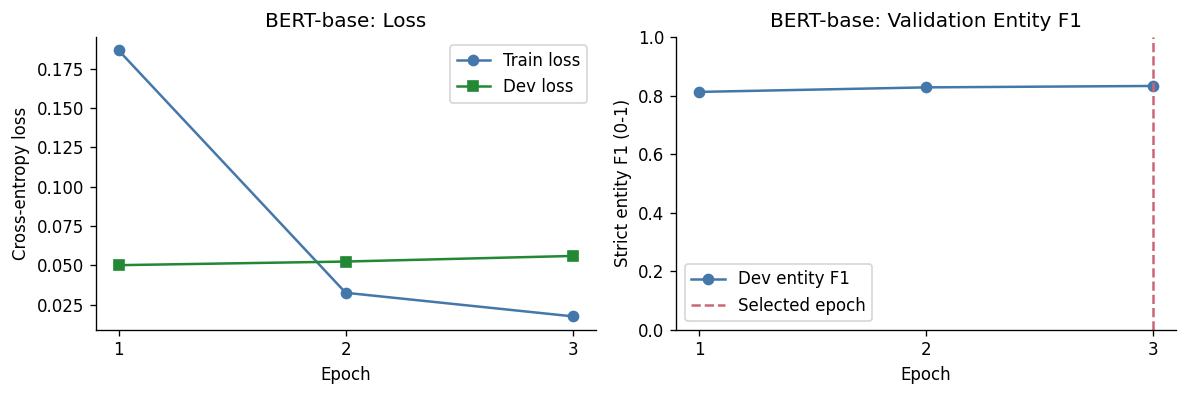

In [41]:
plot_training(bert_history,bert_metrics,ROOT/bert_metrics['result_directory'],'BERT-base')

### 6.3 Baseline observations

In [42]:
describe_run('BERT baseline',bert_metrics,bert_history)

**BERT baseline.** Training loss changed by -0.1692, and Dev F1 by +2.03 percentage points from first to last epoch. Validation loss changed by +0.0059; it weights token confidence rather than exact entity boundaries, so it can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: 3; Dev precision/recall/F1: 0.8069/0.8602/0.8327. The final epoch was selected; longer training has not been tested in this run. The 3-epoch budget and single seed limit the conclusions. Boundary errors, limited training examples, and context lost at chunk boundaries remain possible limitations.

## 7. BioBERT Fine-tuning
### 7.1 Matched-budget experiment

The initial BioBERT run matches BERT's data, seed and three-epoch configuration to compare their pretrained initializations.

Fresh Dev inference verified: biobert/initial (882 sentences).


,epoch,training_loss,validation_loss,precision,recall,f1
0,1.0,0.1884,0.045288,0.839196,0.848793,0.843967
1,2.0,0.0262,0.044638,0.827086,0.869123,0.847584
2,3.0,0.0138,0.048284,0.848596,0.883100,0.865504


,BioBERT initial: freshly verified Dev metrics
precision,0.848596
recall,0.8831
f1,0.865504
validation_loss,0.048284
split,dev
model,dmis-lab/biobert-base-cased-v1.1
run_name,initial
best_epoch,3.0
selected_trainer_checkpoint,checkpoint-966
best_checkpoint,models/biobert/baseline/best


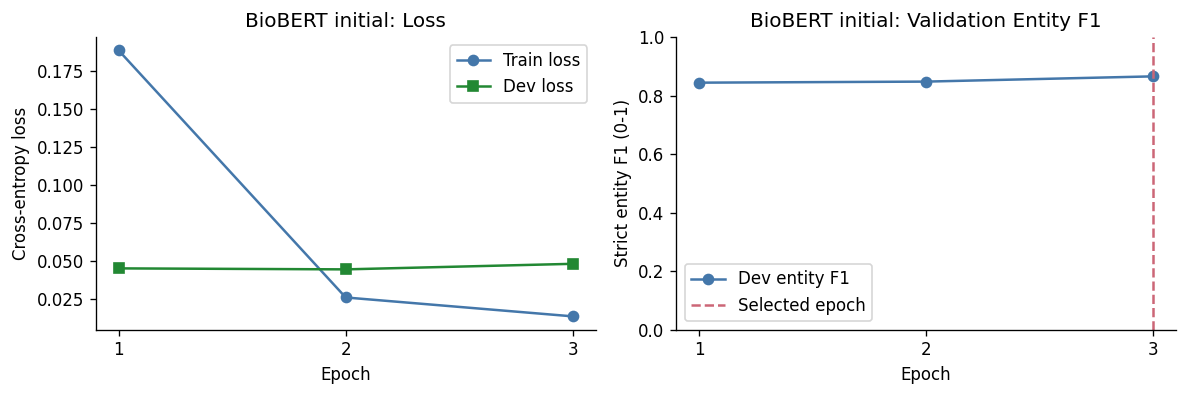

**BioBERT initial.** Training loss changed by -0.1746, and Dev F1 by +2.15 percentage points from first to last epoch. Validation loss changed by +0.0030; it weights token confidence rather than exact entity boundaries, so it can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: 3; Dev precision/recall/F1: 0.8486/0.8831/0.8655. The final epoch was selected; longer training has not been tested in this run. The 3-epoch budget and single seed limit the conclusions. Boundary errors, limited training examples, and context lost at chunk boundaries remain possible limitations.

In [43]:
bio_metrics, bio_history, bio_predictions = run_experiment(ROOT,'biobert','initial',CONFIG,datasets,retrain=RETRAIN)
display(bio_history)
display(pd.Series(bio_metrics).to_frame('BioBERT initial: freshly verified Dev metrics'))
plot_training(bio_history,bio_metrics,ROOT/bio_metrics['result_directory'],'BioBERT initial')
describe_run('BioBERT initial',bio_metrics,bio_history)

## 8. Hyperparameter Experiments
### 8.1 Learning-rate comparison

Compare **2e-5** and **3e-5** with a fixed seed and three epochs. Checkpoint and learning-rate selection use Dev F1.

Fresh Dev inference verified: biobert/lr3e5 (882 sentences).


,epoch,training_loss,validation_loss,precision,recall,f1
0,1.0,0.1672,0.042873,0.840544,0.864041,0.852130
1,2.0,0.0232,0.045284,0.829532,0.878018,0.853086
2,3.0,0.0098,0.050994,0.847666,0.876747,0.861961


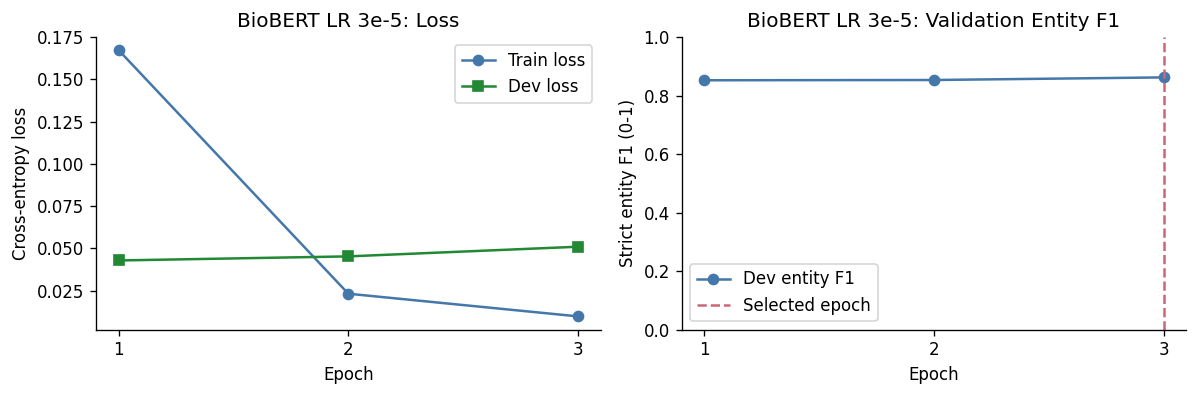

**BioBERT LR candidate.** Training loss changed by -0.1574, and Dev F1 by +0.98 percentage points from first to last epoch. Validation loss changed by +0.0081; it weights token confidence rather than exact entity boundaries, so it can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: 3; Dev precision/recall/F1: 0.8477/0.8767/0.8620. The final epoch was selected; longer training has not been tested in this run. The 3-epoch budget and single seed limit the conclusions. Boundary errors, limited training examples, and context lost at chunk boundaries remain possible limitations.

In [44]:
tuned_config = {**CONFIG,'learning_rate':3e-5}
tuned_metrics, tuned_history, tuned_predictions = run_experiment(ROOT,'biobert','lr3e5',tuned_config,datasets,retrain=RETRAIN)
display(tuned_history)
plot_training(tuned_history,tuned_metrics,ROOT/tuned_metrics['result_directory'],'BioBERT LR 3e-5')
describe_run('BioBERT LR candidate',tuned_metrics,tuned_history)

### 8.2 Epoch-budget comparison

Because initial BioBERT F1 was still rising at epoch 3, the better learning rate was rerun from fresh pretrained weights for five epochs.

The three- and five-epoch budgets use 966/1,610 global steps and 97/161 warmup steps. At epoch 3, their logged learning rates are about `6.90e-8` and `8.93e-6` (before the scheduler update).

The first three epochs therefore follow different optimization trajectories. Any improvement reflects a budget/schedule change, not simply two additional epochs or a different pretrained encoder.

Fresh Dev inference verified: biobert/extended5 (882 sentences).


,epoch,training_loss,validation_loss,precision,recall,f1
0,1.0,0.2214,0.044548,0.842172,0.847522,0.844839
1,2.0,0.0283,0.043830,0.822978,0.891995,0.856098
2,3.0,0.0131,0.054197,0.863579,0.876747,0.870113
3,4.0,0.0065,0.061706,0.859278,0.876747,0.867925
4,5.0,0.0039,0.063634,0.855377,0.879288,0.867168


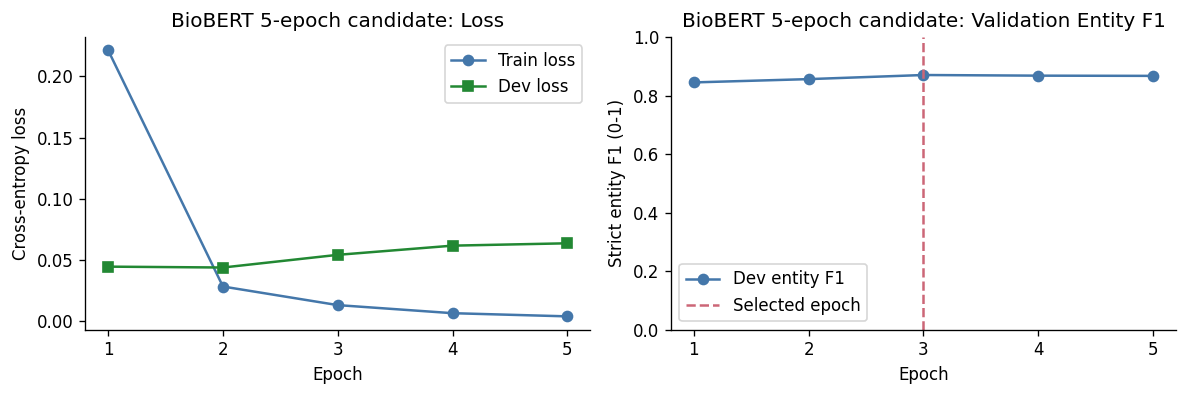

**BioBERT 5-epoch candidate.** Training loss changed by -0.2175, and Dev F1 by +2.23 percentage points from first to last epoch. Validation loss changed by +0.0191; it weights token confidence rather than exact entity boundaries, so it can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: 3; Dev precision/recall/F1: 0.8636/0.8767/0.8701. The final epoch did not exceed the selected Dev F1. The 5-epoch budget and single seed limit the conclusions. Boundary errors, limited training examples, and context lost at chunk boundaries remain possible limitations.

In [45]:
lr_winner = max([bio_metrics,tuned_metrics],key=lambda m:m['f1'])
extended_config = {**CONFIG,'learning_rate':2e-5 if lr_winner['run_name']=='initial' else 3e-5,'num_train_epochs':5}
extended_metrics, extended_history, extended_predictions = run_experiment(ROOT,'biobert','extended5',extended_config,datasets,retrain=RETRAIN)
display(extended_history)
plot_training(extended_history,extended_metrics,ROOT/extended_metrics['result_directory'],'BioBERT 5-epoch candidate')
describe_run('BioBERT 5-epoch candidate',extended_metrics,extended_history)

### 8.3 Model selection

Select the BioBERT run with the highest Dev entity F1, preferring the earlier experiment on ties.

In [46]:
tuning_table = pd.DataFrame([
    {'run':'initial','learning_rate':CONFIG['learning_rate'],'epoch_budget':3,**bio_metrics},
    {'run':'lr3e5','learning_rate':tuned_config['learning_rate'],'epoch_budget':3,**tuned_metrics},
    {'run':'extended5','learning_rate':extended_config['learning_rate'],'epoch_budget':5,**extended_metrics}])
tuning_path = ROOT/'results/biobert'/('tuning_results.csv' if not RETRAIN else f'tuning_results_{RUN_TAG}.csv')
save_table(tuning_table,tuning_path,index=False)
selected_bio = max([bio_metrics,tuned_metrics,extended_metrics],key=lambda m:m['f1'])
display(tuning_table[['run','learning_rate','epoch_budget','best_epoch','precision','recall','f1']])
print('Selected BioBERT run:',selected_bio['run_name'])

,run,learning_rate,epoch_budget,best_epoch,precision,recall,f1
0,initial,0.00002,3,3.0,0.848596,0.883100,0.865504
1,lr3e5,0.00003,3,3.0,0.847666,0.876747,0.861961
2,extended5,0.00002,5,3.0,0.863579,0.876747,0.870113


Selected BioBERT run: extended5


## 9. PubMedBERT Fine-tuning
### 9.1 Model description

[PubMedBERT (BiomedBERT)](https://huggingface.co/microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract)
is pretrained from scratch on PubMed abstracts with a biomedical vocabulary. This tests a
domain-specific initialization and vocabulary against BioBERT's continued pretraining
([Gu et al.](https://arxiv.org/abs/2007.15779)). We use the uncased pretrained encoder and a new NER head.

### 9.2 Training configuration

Use the matched three-epoch configuration and PubMedBERT's own uncased tokenizer.

In [47]:
display(pd.Series({**CONFIG, **TOKENIZER_OPTIONS['pubmedbert'],
    'model':MODEL_CONFIGS['pubmedbert'], 'revision':MODEL_REVISIONS['pubmedbert']}).to_frame('PubMedBERT configuration'))

,PubMedBERT configuration
learning_rate,0.00002
batch_size,8
gradient_accumulation_steps,2
num_train_epochs,3
max_length,128
weight_decay,0.01
warmup_ratio,0.1
seed,42
fp16,True
do_lower_case,True


### 9.3 Training and validation

The shared pipeline selects the checkpoint with the highest Dev strict entity F1.

In [48]:
pubmed_metrics, pubmed_history, pubmed_predictions = run_experiment(
    ROOT,'pubmedbert','baseline',CONFIG,datasets,retrain=should_train('pubmedbert'))
display(pubmed_history)

Fresh Dev inference verified: pubmedbert/baseline (882 sentences).


,epoch,training_loss,validation_loss,precision,recall,f1
0,1.0,0.1736,0.042360,0.784580,0.879288,0.829239
1,2.0,0.0271,0.046226,0.802800,0.874206,0.836983
2,3.0,0.0133,0.050003,0.855377,0.879288,0.867168


### 9.4 Results

,PubMedBERT Dev results
precision,0.855377
recall,0.879288
f1,0.867168
validation_loss,0.050003
split,dev
model,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...
run_name,baseline
best_epoch,3.0
selected_trainer_checkpoint,checkpoint-963
best_checkpoint,models/pubmedbert/baseline/best


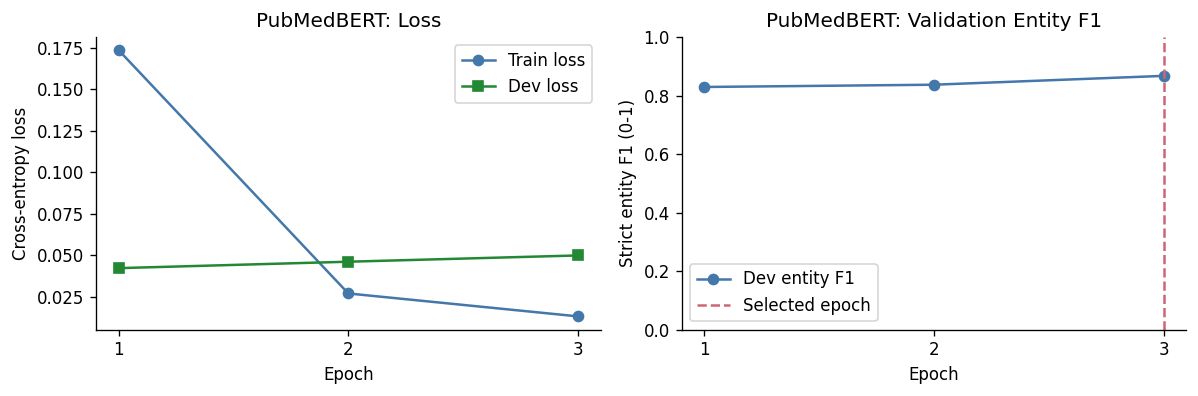

**PubMedBERT.** Training loss changed by -0.1603, and Dev F1 by +3.79 percentage points from first to last epoch. Validation loss changed by +0.0076; it weights token confidence rather than exact entity boundaries, so it can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: 3; Dev precision/recall/F1: 0.8554/0.8793/0.8672. The final epoch was selected; longer training has not been tested in this run. The 3-epoch budget and single seed limit the conclusions. Boundary errors, limited training examples, and context lost at chunk boundaries remain possible limitations.

In [49]:
display(pd.Series(pubmed_metrics).to_frame('PubMedBERT Dev results'))
plot_training(pubmed_history,pubmed_metrics,ROOT/pubmed_metrics['result_directory'],'PubMedBERT')
describe_run('PubMedBERT',pubmed_metrics,pubmed_history)

## 10. SciBERT Fine-tuning
### 10.1 Model description

[SciBERT](https://huggingface.co/allenai/scibert_scivocab_cased) is pretrained on scientific
publications using SciVocab, a vocabulary built from that corpus
([Beltagy et al., 2019](https://aclanthology.org/D19-1371/)). The cased model tests scientific-domain
representations while preserving capitalization; it starts from pretrained weights with a new NER head.

### 10.2 Training configuration

Use the same three-epoch settings and SciBERT's own cased tokenizer.

In [50]:
display(pd.Series({**CONFIG, **TOKENIZER_OPTIONS['scibert'],
    'model':MODEL_CONFIGS['scibert'], 'revision':MODEL_REVISIONS['scibert']}).to_frame('SciBERT configuration'))

,SciBERT configuration
learning_rate,0.00002
batch_size,8
gradient_accumulation_steps,2
num_train_epochs,3
max_length,128
weight_decay,0.01
warmup_ratio,0.1
seed,42
fp16,True
do_lower_case,False


### 10.3 Training and validation

Train and select checkpoints with the same Dev evaluation procedure.

In [51]:
sci_metrics, sci_history, sci_predictions = run_experiment(
    ROOT,'scibert','baseline',CONFIG,datasets,retrain=should_train('scibert'))
display(sci_history)

Fresh Dev inference verified: scibert/baseline (882 sentences).


,epoch,training_loss,validation_loss,precision,recall,f1
0,1.0,0.1419,0.044101,0.779775,0.881830,0.827668
1,2.0,0.0279,0.043961,0.819378,0.870394,0.844116
2,3.0,0.0137,0.048541,0.847584,0.869123,0.858218


### 10.4 Results

,SciBERT Dev results
precision,0.847584
recall,0.869123
f1,0.858218
validation_loss,0.048541
split,dev
model,allenai/scibert_scivocab_cased
run_name,baseline
best_epoch,3.0
selected_trainer_checkpoint,checkpoint-963
best_checkpoint,models/scibert/baseline/best


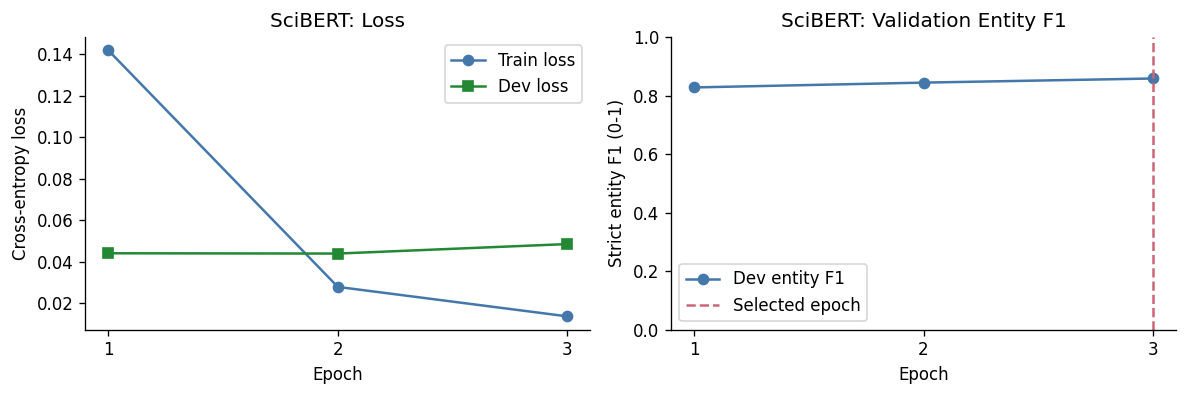

**SciBERT.** Training loss changed by -0.1282, and Dev F1 by +3.05 percentage points from first to last epoch. Validation loss changed by +0.0044; it weights token confidence rather than exact entity boundaries, so it can diverge from entity F1. Checkpoint selection follows Dev entity F1. Best epoch: 3; Dev precision/recall/F1: 0.8476/0.8691/0.8582. The final epoch was selected; longer training has not been tested in this run. The 3-epoch budget and single seed limit the conclusions. Boundary errors, limited training examples, and context lost at chunk boundaries remain possible limitations.

In [52]:
display(pd.Series(sci_metrics).to_frame('SciBERT Dev results'))
plot_training(sci_history,sci_metrics,ROOT/sci_metrics['result_directory'],'SciBERT')
describe_run('SciBERT',sci_metrics,sci_history)

## 11. Model Comparison
### 11.1 Matched-budget Dev results

The four baselines share a three-epoch configuration and seed. BioBERT uses its Initial run;
the tuned checkpoints are compared separately. Vocabulary, casing and chunk counts differ,
so the results do not isolate the effect of pretraining text.

In [53]:
from IPython.display import Image

COMPARISON = ROOT/'results/comparison'
comparison_suffix = f'_{RUN_TAG}' if RETRAIN else ''
strategies = {'bert_base':'General-domain', 'biobert':'Continued biomedical pretraining',
              'pubmedbert':'Biomedical pretraining from scratch', 'scibert':'Scientific-domain pretraining'}

def read_comparison_run(name, key, verified):
    directory = ROOT/verified['result_directory']
    saved = json.loads((directory/'validation_metrics.json').read_text())
    history = pd.read_csv(directory/'training_history.csv')
    record = json.loads((directory/'training_config.json').read_text())
    config = record['signature']['hyperparameters']
    best = history.loc[history.f1.idxmax()]
    assert saved['best_checkpoint'] == verified['best_checkpoint']
    assert saved['checkpoint_sha256'] == verified['checkpoint_sha256']
    assert saved['best_epoch'] == best['epoch']
    assert all(abs(saved[k]-best[k]) < 1e-12 for k in ['precision','recall','f1'])
    assert all(abs(saved[k]-verified[k]) < 1e-12 for k in ['precision','recall','f1'])
    row = {'Model':name,'model_key':key,'Pretraining Strategy':strategies[key],
           'LR':config['learning_rate'],'epoch_budget':config['num_train_epochs'],**saved}
    sources = {filename:{'path':(directory/filename).relative_to(ROOT).as_posix(),
                         'sha256':sha256(directory/filename)} for filename in
               ['validation_metrics.json','training_history.csv','training_config.json']}
    return row, history, record, sources

In [54]:
def render_comparison(fig, stem, aliases=()):
    path = COMPARISON/f'{stem}{comparison_suffix}.png'
    fig.tight_layout()
    fig.savefig(path, bbox_inches='tight')
    for alias in aliases:
        shutil.copyfile(path, COMPARISON/f'{alias}{comparison_suffix}.png')
    plt.close(fig)
    display(Image(filename=str(path)))

In [55]:
baseline_specs = [('BERT-base','bert_base',bert_metrics),('BioBERT Initial','biobert',bio_metrics),
                  ('PubMedBERT','pubmedbert',pubmed_metrics),('SciBERT','scibert',sci_metrics)]
baseline_runs = [read_comparison_run(*spec) for spec in baseline_specs]
baseline_rows = [run[0] for run in baseline_runs]
baseline_comparison = pd.DataFrame(baseline_rows)
assert baseline_comparison['epoch_budget'].eq(CONFIG['num_train_epochs']).all()
columns = ['Model','Pretraining Strategy','split','LR','epoch_budget','best_epoch','precision','recall','f1']
display(baseline_comparison[columns])
for stem in ['model_comparison','four_model_comparison']:
    baseline_comparison.to_csv(COMPARISON/f'{stem}{comparison_suffix}.csv',index=False)

baseline_summary = {'split':'dev','evaluation':'seqeval strict IOB2 entity precision/recall/F1',
    'selection':'maximum Dev entity F1; earliest epoch on ties',
    'models':baseline_rows,'source_files':{run[0]['Model']:run[3] for run in baseline_runs},
    'limitations':['Single seed (42); Dev-based selection.',
                   'Vocabulary, casing and tokenizer-dependent update counts differ.']}
_ = (COMPARISON/f'baseline_metrics_summary{comparison_suffix}.json').write_text(
    json.dumps(baseline_summary,indent=2,allow_nan=False),encoding='utf-8')

,Model,Pretraining Strategy,split,LR,epoch_budget,best_epoch,precision,recall,f1
0,BERT-base,General-domain,dev,0.00002,3,3.0,0.806913,0.860229,0.832718
1,BioBERT Initial,Continued biomedical pretraining,dev,0.00002,3,3.0,0.848596,0.883100,0.865504
2,PubMedBERT,Biomedical pretraining from scratch,dev,0.00002,3,3.0,0.855377,0.879288,0.867168
3,SciBERT,Scientific-domain pretraining,dev,0.00002,3,3.0,0.847584,0.869123,0.858218


### 11.2 Baseline visualizations

Scores use the selected checkpoint from each three-epoch run. Validation loss measures
token confidence, depends on tokenization, and is not the checkpoint-selection metric.

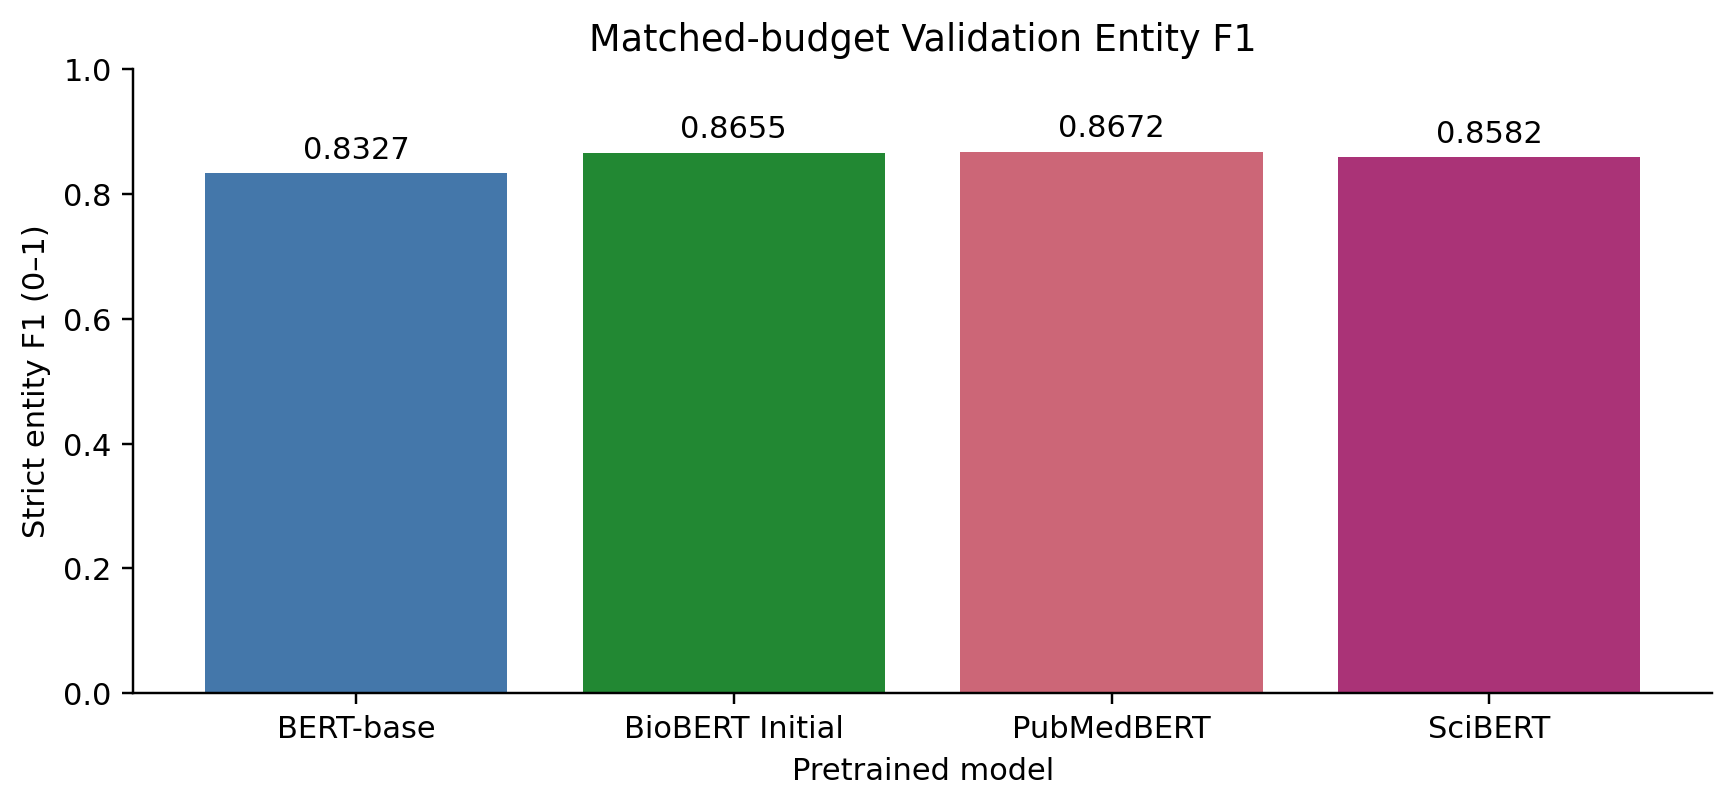

In [56]:
baseline_palette = ['#4477AA','#228833','#CC6677','#AA3377']
fig,ax = plt.subplots(figsize=(8,3.8))
bars = ax.bar(baseline_comparison['Model'],baseline_comparison['f1'],color=baseline_palette)
ax.bar_label(bars,labels=[f'{x:.4f}' for x in baseline_comparison['f1']],padding=3)
ax.set(title='Matched-budget Validation Entity F1',xlabel='Pretrained model',
       ylabel='Strict entity F1 (0–1)',ylim=(0,1))
render_comparison(fig,'model_comparison',aliases=('four_model_f1',))

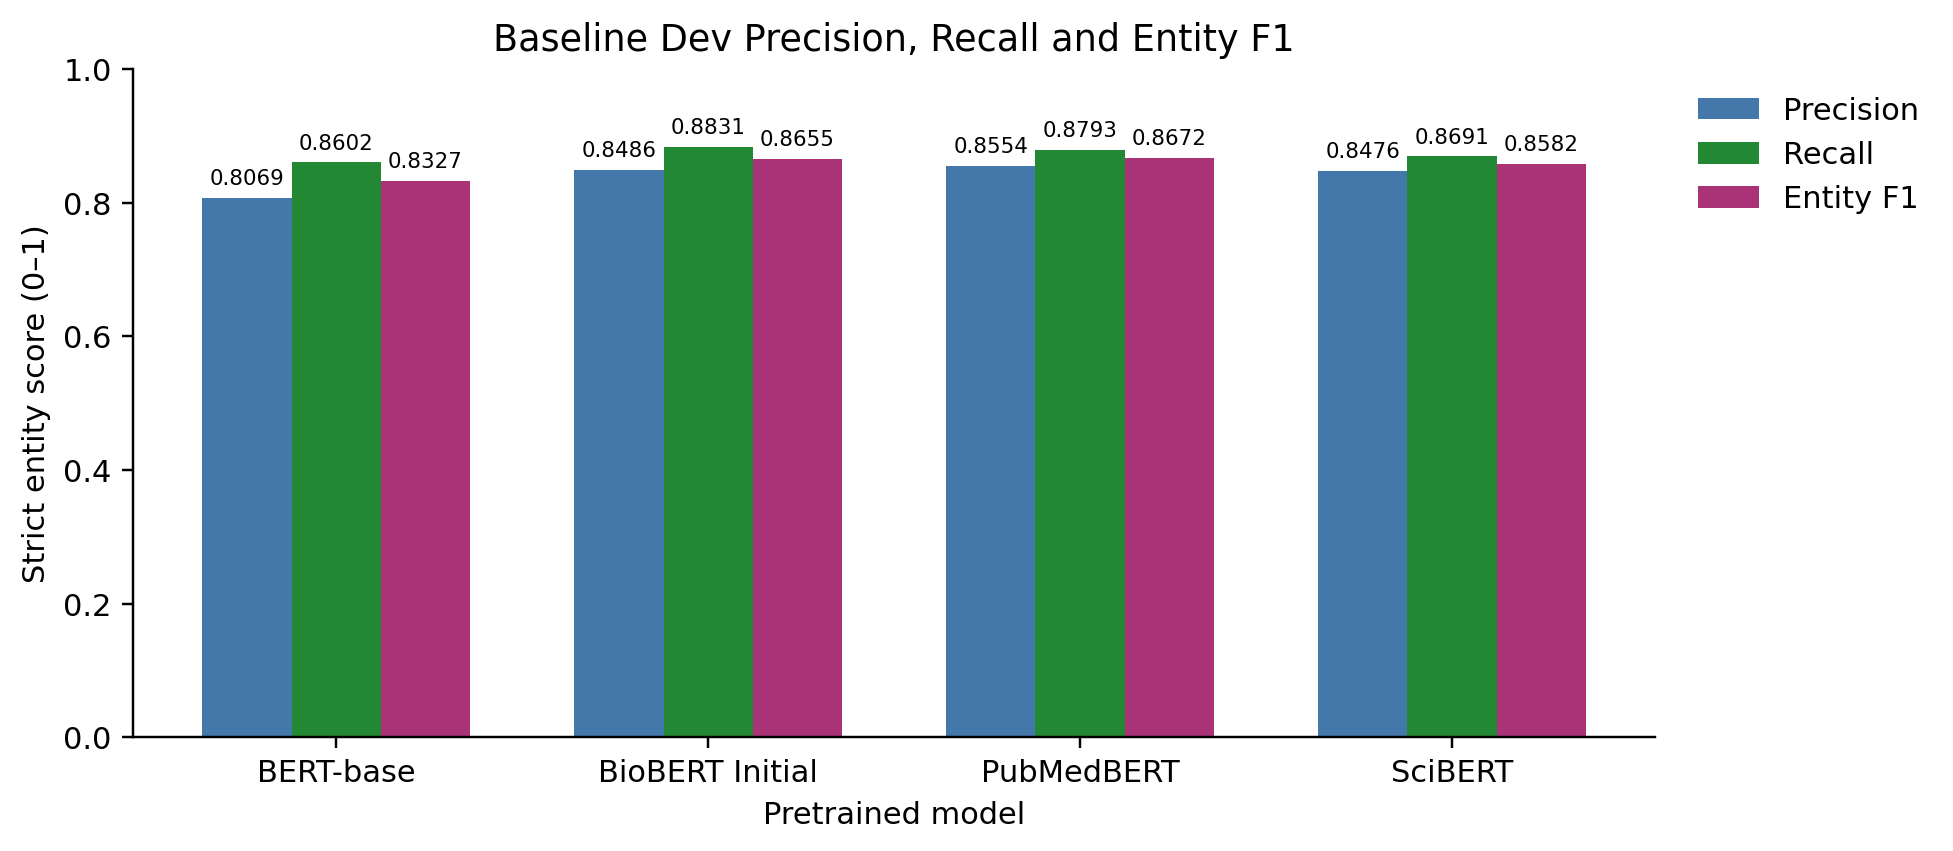

In [57]:
fig,ax = plt.subplots(figsize=(9,4))
x = np.arange(len(baseline_comparison))
width = 0.24
for offset,(metric,label,color) in enumerate(zip(
        ['precision','recall','f1'],['Precision','Recall','Entity F1'],['#4477AA','#228833','#AA3377'])):
    values = baseline_comparison[metric]
    bars = ax.bar(x+(offset-1)*width,values,width,label=label,color=color)
    ax.bar_label(bars,labels=[f'{v:.4f}' for v in values],padding=3,fontsize=7)
ax.set(xticks=x,xticklabels=baseline_comparison['Model'],ylim=(0,1),
       title='Baseline Dev Precision, Recall and Entity F1',xlabel='Pretrained model',ylabel='Strict entity score (0–1)')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
render_comparison(fig,'precision_recall_f1_comparison')

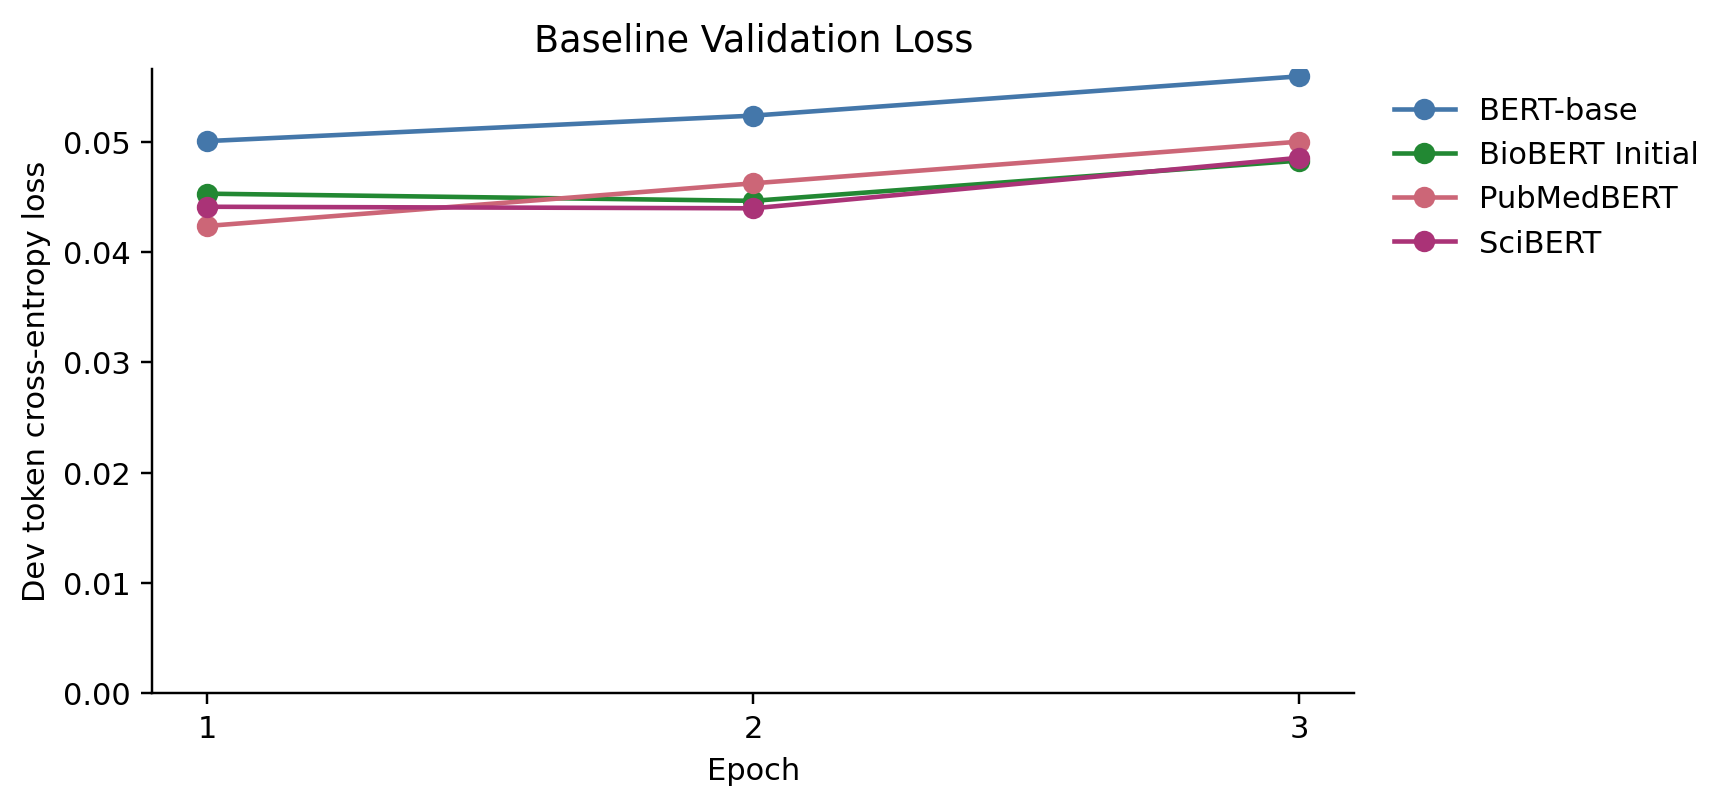

In [58]:
validation_history = pd.concat([history.assign(Model=row['Model'])
    for row,history,record,sources in baseline_runs],ignore_index=True)
validation_history.to_csv(COMPARISON/f'baseline_validation_history{comparison_suffix}.csv',index=False)
fig,ax = plt.subplots(figsize=(8,3.8))
for (row,history,record,sources),color in zip(baseline_runs,baseline_palette):
    ax.plot(history['epoch'],history['validation_loss'],'o-',label=row['Model'],color=color)
ax.set(title='Baseline Validation Loss',xlabel='Epoch',ylabel='Dev token cross-entropy loss',
       xticks=sorted(validation_history['epoch'].unique()),ylim=(0,None))
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
render_comparison(fig,'validation_loss_comparison')

### 11.3 Training configuration

The epoch budget is shared; tokenizer-dependent chunk counts produce slightly different update counts.

In [59]:
settings_rows = []
for row,history,record,sources in baseline_runs:
    key = row['model_key']
    config = record['signature']['hyperparameters']
    log = json.loads((ROOT/row['result_directory']/'trainer_log.json').read_text())
    source_config = record['model_source']['source_config']
    audit = tokenization_audit[(tokenization_audit['model']==key) & (tokenization_audit['split']=='train')].iloc[0]
    settings_rows.append({'Model':row['Model'],'model_key':key,**config,**TOKENIZER_OPTIONS[key],
        'effective_batch_size':config['batch_size']*config['gradient_accumulation_steps'],
        'vocabulary_size':len(tokenizers[key]),'optimizer':'AdamW','scheduler':'linear',
        'selection':'Dev strict IOB2 entity F1','revision':record['signature']['pretrained_revision'],
        'embedding_vocabulary_capacity':source_config['vocab_size'],
        'encoded_train_chunks':int(audit['encoded_chunks']),'global_steps':log[-1]['step'],
        'warmup_steps':int(np.ceil(log[-1]['step']*config['warmup_ratio']))})
settings = pd.DataFrame(settings_rows)
display(settings[['Model','do_lower_case','vocabulary_size','encoded_train_chunks','global_steps','warmup_steps']])
settings.to_csv(COMPARISON/f'four_model_training_settings{comparison_suffix}.csv',index=False)
tokenization_audit.to_csv(COMPARISON/f'four_model_tokenization_audit{comparison_suffix}.csv',index=False)
tokenization_audit.to_csv(ROOT/'results/eda'/f'tokenization_audit{comparison_suffix}.csv',index=False)

smoke_path = ROOT/'results/smoke_test.json'
smoke_summary = json.loads(smoke_path.read_text())
for key in NEW_MODEL_KEYS:
    smoke_summary[key] = json.loads((ROOT/'results'/key/'smoke_test.json').read_text())
if not RETRAIN:
    smoke_path.write_text(json.dumps(smoke_summary,indent=2),encoding='utf-8')

,Model,do_lower_case,vocabulary_size,encoded_train_chunks,global_steps,warmup_steps
0,BERT-base,False,28996,5139,966,97
1,BioBERT Initial,False,28996,5139,966,97
2,PubMedBERT,True,28895,5135,963,97
3,SciBERT,False,31116,5135,963,97


### 11.4 BioBERT tuning

Compare Initial, the learning-rate candidate and Selected / Extended5 separately.
The five-epoch run has a different budget and learning-rate trajectory; its selected epoch is reported in the table.

In [60]:
tuning_runs = [baseline_runs[1],
    read_comparison_run('BioBERT LR Candidate','biobert',tuned_metrics),
    read_comparison_run('BioBERT Selected / Extended5','biobert',extended_metrics)]
tuning_rows = [{'run':row['run_name'],'learning_rate':row['LR'],**row}
               for row,history,record,sources in tuning_runs]
tuning_comparison = pd.DataFrame(tuning_rows)
display(tuning_comparison[['Model','learning_rate','epoch_budget','best_epoch','precision','recall','f1']])
tuning_comparison.to_csv(COMPARISON/f'biobert_tuning_comparison{comparison_suffix}.csv',index=False)
tuning_comparison.to_csv(ROOT/'results/biobert'/f'tuning_results{comparison_suffix}.csv',index=False)

,Model,learning_rate,epoch_budget,best_epoch,precision,recall,f1
0,BioBERT Initial,0.00002,3,3.0,0.848596,0.883100,0.865504
1,BioBERT LR Candidate,0.00003,3,3.0,0.847666,0.876747,0.861961
2,BioBERT Selected / Extended5,0.00002,5,3.0,0.863579,0.876747,0.870113


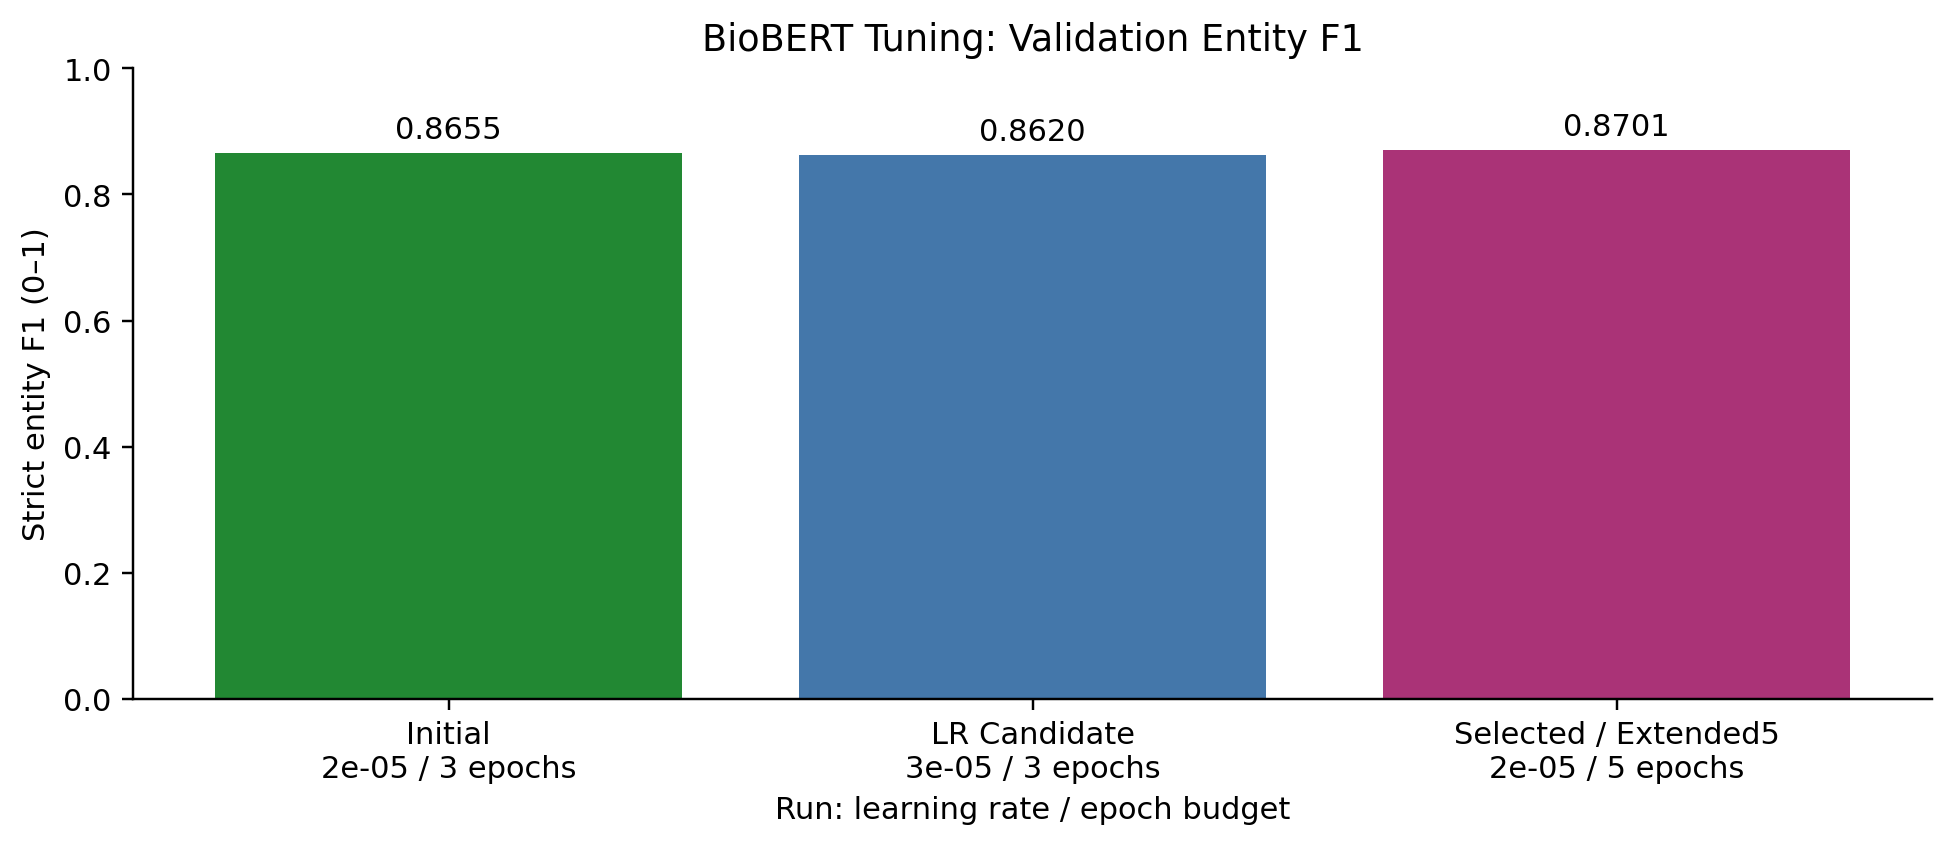

In [61]:
fig,ax = plt.subplots(figsize=(9,4))
labels = [f"{name}\n{row['LR']:.0e} / {int(row['epoch_budget'])} epochs"
          for name,row in zip(['Initial','LR Candidate','Selected / Extended5'],tuning_rows)]
bars = ax.bar(labels,tuning_comparison['f1'],color=['#228833','#4477AA','#AA3377'])
ax.bar_label(bars,labels=[f'{v:.4f}' for v in tuning_comparison['f1']],padding=3)
ax.set(title='BioBERT Tuning: Validation Entity F1',xlabel='Run: learning rate / epoch budget',
       ylabel='Strict entity F1 (0–1)',ylim=(0,1))
render_comparison(fig,'biobert_tuning_comparison')

### 11.5 Interpretation

These are single-seed estimates, and repeated Dev-based selection may make the selected score optimistic. The differences do not establish statistical significance or general clinical performance.

In [62]:
delta = 100*(bio_metrics['f1']-bert_metrics['f1'])
tune_delta = 100*(tuned_metrics['f1']-bio_metrics['f1'])
budget_delta = 100*(extended_metrics['f1']-lr_winner['f1'])
display(Markdown(f"At matched settings, BioBERT's Dev F1 differs from BERT by **{delta:+.2f} percentage "
    f"points**. Changing only BioBERT's learning rate from 2e-5 to 3e-5 changes best Dev F1 by "
    f"**{tune_delta:+.2f} points**. The 5-epoch budget/schedule changes the LR winner's best Dev F1 by "
    f"**{budget_delta:+.2f} points**. Selected BioBERT run: **{selected_bio['run_name']}**, Dev F1 "
    f"**{selected_bio['f1']:.4f}**. Domain pretraining is a plausible explanation for an initial-model "
    'difference, but one seed cannot separate it from optimization variation.'))

display(Markdown(f"At the shared three-epoch settings, PubMedBERT differs from BERT by "
    f"{100*(pubmed_metrics['f1']-bert_metrics['f1']):+.2f} F1 points and from BioBERT Initial by "
    f"{100*(pubmed_metrics['f1']-bio_metrics['f1']):+.2f} points. SciBERT differs from BERT by "
    f"{100*(sci_metrics['f1']-bert_metrics['f1']):+.2f} points and from BioBERT Initial by "
    f"{100*(sci_metrics['f1']-bio_metrics['f1']):+.2f} points. These single-seed results reflect "
    'pretraining strategy, vocabulary and casing together; the experiment does not isolate their individual effects.'))


At matched settings, BioBERT's Dev F1 differs from BERT by **+3.28 percentage points**. Changing only BioBERT's learning rate from 2e-5 to 3e-5 changes best Dev F1 by **-0.35 points**. The 5-epoch budget/schedule changes the LR winner's best Dev F1 by **+0.46 points**. Selected BioBERT run: **extended5**, Dev F1 **0.8701**. Domain pretraining is a plausible explanation for an initial-model difference, but one seed cannot separate it from optimization variation.

At the shared three-epoch settings, PubMedBERT differs from BERT by +3.44 F1 points and from BioBERT Initial by +0.17 points. SciBERT differs from BERT by +2.55 points and from BioBERT Initial by -0.73 points. These single-seed results reflect pretraining strategy, vocabulary and casing together; the experiment does not isolate their individual effects.

**Published reference results.** The [official BioBERT PyTorch repository](https://github.com/dmis-lab/biobert-pytorch/tree/master/named-entity-recognition) reports NCBI-disease **Test F1** of 85.27% for BERT and 88.30% for BioBERT, alongside a 30-epoch recipe with maximum length 192 and batch size 32. These reference values are separate from our Dev results; differences in split, preprocessing, seed and budget prevent a direct SOTA comparison.

### 11.6 Prediction consistency

Each prediction sequence must cover all original tokens and reproduce the reported entity metrics.

In [63]:
acceptance = []
for key,run,metrics,predicted in [('bert_base','baseline',bert_metrics,bert_predictions),
    ('biobert','initial',bio_metrics,bio_predictions),('biobert','lr3e5',tuned_metrics,tuned_predictions),
    ('biobert','extended5',extended_metrics,extended_predictions),
    ('pubmedbert','baseline',pubmed_metrics,pubmed_predictions),
    ('scibert','baseline',sci_metrics,sci_predictions)]:
    assert len(predicted) == len(datasets['dev'])
    assert all(len(tags)==len(sample['tokens']) for tags,sample in zip(predicted,datasets['dev']))
    recomputed = entity_metrics([s['ner_tags'] for s in datasets['dev']],predicted)
    assert all(abs(recomputed[k]-metrics[k])<1e-12 for k in recomputed)
    assert metrics['checkpoint_reload_verified']
    acceptance.append({'run':f'{key}/{run}','sentences':len(predicted),
        'fresh_dev_f1':recomputed['f1'],'checkpoint_verified':True,
        'role':'baseline' if (key,run) in {('bert_base','baseline'),('biobert','initial'),
            ('pubmedbert','baseline'),('scibert','baseline')} else 'tuning',
        'best_checkpoint':metrics['best_checkpoint'],'result_directory':metrics['result_directory']})
display(pd.DataFrame(acceptance))

acceptance_summary = {'runs':acceptance,'data_validation':validation['status'],
    'test_evaluated':False,'single_seed':CONFIG['seed'],'notebook':'notebooks/project013.ipynb'}
_ = (COMPARISON/f'acceptance{comparison_suffix}.json').write_text(
    json.dumps(acceptance_summary,indent=2),encoding='utf-8')


,run,sentences,fresh_dev_f1,checkpoint_verified,role,best_checkpoint,result_directory
0,bert_base/baseline,882,0.832718,True,baseline,models/bert_base/baseline/best,results/bert_base/baseline
1,biobert/initial,882,0.865504,True,baseline,models/biobert/baseline/best,results/biobert/baseline
2,biobert/lr3e5,882,0.861961,True,tuning,models/biobert/tuning/lr3e5/best,results/biobert/tuning/lr3e5
3,biobert/extended5,882,0.870113,True,tuning,models/biobert/tuning/extended5/best,results/biobert/tuning/extended5
4,pubmedbert/baseline,882,0.867168,True,baseline,models/pubmedbert/baseline/best,results/pubmedbert/baseline
5,scibert/baseline,882,0.858218,True,baseline,models/scibert/baseline/best,results/scibert/baseline


### 11.7 References

1. Doğan, R. I., Leaman, R., & Lu, Z. (2014). NCBI disease corpus: a resource for disease name recognition
   and concept normalization. [Journal of Biomedical Informatics](https://doi.org/10.1016/j.jbi.2013.12.006).
2. Devlin, J., et al. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language
   Understanding. [ACL Anthology](https://aclanthology.org/N19-1423/).
3. Lee, J., et al. (2020). BioBERT: a pre-trained biomedical language representation model for
   biomedical text mining. [Bioinformatics](https://doi.org/10.1093/bioinformatics/btz682).
4. [Official BioBERT repository](https://github.com/dmis-lab/biobert) and
   [PyTorch implementation](https://github.com/dmis-lab/biobert-pytorch).
5. [Hugging Face token-classification task guide](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/token_classification)
   and [seqeval strict IOB2 evaluation](https://github.com/chakki-works/seqeval).

6. Gu, Y., et al. (2021). Domain-Specific Language Model Pretraining for Biomedical Natural
   Language Processing. [Paper](https://arxiv.org/abs/2007.15779),
   [pretrained BiomedBERT](https://huggingface.co/microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract).
7. Beltagy, I., Lo, K., & Cohan, A. (2019). SciBERT: A Pretrained Language Model for Scientific Text.
   [EMNLP-IJCNLP](https://aclanthology.org/D19-1371/),
   [pretrained cased SciBERT](https://huggingface.co/allenai/scibert_scivocab_cased).
